In [3]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Config

In [4]:
import os, re, glob, json, time, random, hashlib, zipfile, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed, dump
from tqdm.auto import tqdm
from scipy import signal
from scipy.signal import find_peaks
from numpy.lib.stride_tricks import sliding_window_view

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---- folders ----
OUTPUT_DIR = '/content/drive/MyDrive/SENTINEL_X'
PLOT_DIR = f'{OUTPUT_DIR}/plots'
SISFALL_REPO_DIR = '/content/sisfall_repo'
SISFALL_DIR = '/content/extracted_sisfall'
os.makedirs(PLOT_DIR, exist_ok=True)

# ---- SisFall file format ----
RAW_FS_HZ = 200
ACC_COLUMNS = [0, 1, 2]                  # ADXL345 only (not the second accelerometer)
GYRO_COLUMNS = [3, 4, 5]                 # ITG3200
ACC_G_PER_COUNT = 2 * 16 / 2**13         # +-16 g, 13 bit
# The paper's formula and the ITG3200 datasheet differ by about 14 %. Verify against the dataset
# documentation, pick one, and rerun everything from Cell 8 if you change it.
GYRO_SCALE = 'datasheet'                 # 'paper' or 'datasheet'
GYRO_DPS_PER_COUNT = {'paper': 2 * 2000 / 2**16, 'datasheet': 1 / 14.375}[GYRO_SCALE]

# ---- model input ----
MODEL_FS_HZ = 50
DECIMATION = RAW_FS_HZ // MODEL_FS_HZ
LOWPASS_CUTOFF_HZ, LOWPASS_ORDER = 20, 4
WINDOW_LEN, WINDOW_STRIDE = 100, 50      # 2 s windows with 50 % overlap
IMPACT_MIN_POS, IMPACT_MAX_POS = 20, 80  # a fall window must hold the impact inside this range
MIN_RECORDING_S = 5
SPLIT_NAMES = ('train', 'val', 'test')

# ---- hardware: MPU6050 on the ESP32 (firmware must use the same settings) ----
HARDWARE = dict(
    imu='MPU6050',
    sample_rate_hz=200,                  # SMPLRT_DIV = 4 with DLPF on
    dlpf_setting=2,                      # CONFIG = 0x02 (about 94 Hz internal filter)
    accel_counts_per_g=2048.0,           # +-16 g
    gyro_counts_per_dps=16.4,            # +-2000 deg/s
    axis_map=np.eye(3).tolist(),         # device -> SisFall frame, filled in Cell 29
)


def save_figure(name):
    plt.savefig(f'{PLOT_DIR}/{name}.png', dpi=150, bbox_inches='tight')


def seconds_to_samples(seconds):
    return int(round(seconds * MODEL_FS_HZ))


def acc_magnitude(sig):
    return np.linalg.norm(sig[:, :3], axis=1)


def gyro_magnitude(sig):
    return np.linalg.norm(sig[:, 3:], axis=1)


def tilt_angle_deg(vec_a, vec_b):
    """Angle in degrees between two gravity vectors (one pair, or many pairs stacked in rows)."""
    dot = (vec_a * vec_b).sum(-1)
    norms = np.linalg.norm(vec_a, axis=-1) * np.linalg.norm(vec_b, axis=-1) + 1e-8
    return np.degrees(np.arccos(np.clip(dot / norms, -1, 1)))

# download and extract


In [5]:
from huggingface_hub import snapshot_download


def download_and_extract_sisfall():
    if glob.glob(f'{SISFALL_DIR}/**/*.txt', recursive=True):
        print('SisFall already extracted')
        return
    snapshot_download(repo_id='abys7315/Sisfall_Dataset', repo_type='dataset', local_dir=SISFALL_REPO_DIR)
    os.makedirs(SISFALL_DIR, exist_ok=True)
    with zipfile.ZipFile(f'{SISFALL_REPO_DIR}/SisFall_dataset.zip') as zip_file:
        zip_file.extractall(SISFALL_DIR)


download_and_extract_sisfall()
print('top level:', os.listdir(SISFALL_DIR)[:10])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

top level: ['SisFall_dataset', '__MACOSX']


# find recording and verify the list

In [6]:
FILENAME_PATTERN = re.compile(r'^([DF]\d{2})_(S[AE]\d{2})_R(\d+)\.txt$', re.I)   # e.g. F05_SA12_R03.txt


def find_recordings(root_dir):
    """Return a table with one row per SisFall file, plus the names of .txt files that did not match."""
    rows, skipped = [], []
    for path in sorted(glob.glob(f'{root_dir}/**/*.txt', recursive=True)):
        match = FILENAME_PATTERN.match(os.path.basename(path))
        if match is None:
            skipped.append(os.path.basename(path))
            continue
        rows.append(dict(path=path, activity=match.group(1).upper(),
                         subject=match.group(2).upper(), trial=int(match.group(3))))
    table = pd.DataFrame(rows)
    table['recording_id'] = (table.activity + '_' + table.subject + '_R' +
                             table.trial.astype(str).str.zfill(2))
    return table, skipped


def resolve_duplicate_ids(table):
    """If an id appears twice: drop byte-identical copies, keep genuinely different files with a suffix."""
    is_duplicate = table.recording_id.duplicated(keep=False)
    if not is_duplicate.any():
        return table
    duplicates = table[is_duplicate].copy()
    duplicates['md5'] = duplicates.path.map(lambda p: hashlib.md5(open(p, 'rb').read()).hexdigest())
    distinct = duplicates.drop_duplicates(['recording_id', 'md5']).drop(columns='md5')
    print(f'{len(duplicates)} files share an id -> {len(distinct)} distinct (identical copies dropped)')
    table = pd.concat([table[~is_duplicate], distinct], ignore_index=True)
    copy_number = table.groupby('recording_id').cumcount()
    table.loc[copy_number > 0, 'recording_id'] += '_v' + copy_number[copy_number > 0].astype(str)
    return table


recordings, skipped_files = find_recordings(SISFALL_DIR)
recordings = resolve_duplicate_ids(recordings)
print('recordings found :', len(recordings), '(SisFall has about 4,500)')
print('files skipped    :', len(skipped_files), skipped_files[:5])
print('fall recordings  :', int(recordings.activity.str.startswith('F').sum()))
print('subjects         :', recordings.subject.nunique())

10 files share an id -> 10 distinct (identical copies dropped)
recordings found : 4505 (SisFall has about 4,500)
files skipped    : 1 ['Readme.txt']
fall recordings  : 1798
subjects         : 38


# Insepect the one raw file

In [7]:
def inspect_raw_file(path, n_preview=3):
    with open(path) as f:
        lines = f.read().splitlines()
    print(path, '| lines:', len(lines))
    for line in lines[:n_preview]:
        print('  ', repr(line))
    fields_per_line = pd.Series([len(l.rstrip(';').split(',')) for l in lines]).value_counts().to_dict()
    values = np.array([[float(v) for v in l.strip().rstrip(';').split(',')] for l in lines if l.strip()])
    print('fields per line:', fields_per_line)
    print('shape:', values.shape, '| duration at 200 Hz:', len(values) / RAW_FS_HZ, 's')
    print('min per column:', values.min(0))
    print('max per column:', values.max(0))


inspect_raw_file(recordings.path.iloc[0])

/content/extracted_sisfall/SisFall_dataset/SA01/D01_SA01_R01.txt | lines: 19999
   '  17,-179, -99, -18,-504,-352,  76,-697,-279;'
   '  15,-174, -90, -53,-568,-306,  48,-675,-254;'
   '   1,-176, -81, -84,-613,-271,  -2,-668,-221;'
fields per line: {9: 19999}
shape: (19999, 9) | duration at 200 Hz: 99.995 s
min per column: [ -113.  -506.  -217. -1037. -1479. -1365.  -432. -1928.  -759.]
max per column: [ 146. -118.  118. 1171. 1158. 1228.  540. -456.  586.]


# labels

In [8]:
recordings['label'] = recordings.activity.str.startswith('F').astype(int)               # 0 = ADL, 1 = fall
recordings['age_group'] = np.where(recordings.subject.str.startswith('SA'), 'young', 'elderly')

print(recordings.groupby(['age_group', 'label']).size().unstack(fill_value=0).rename(columns={0: 'ADL', 1: 'Fall'}))
print('\nrecordings per subject (fall recordings in the second row):')
print(recordings.groupby('subject').label.agg(files='size', falls='sum').T.to_string())

label       ADL  Fall
age_group            
elderly     898    75
young      1809  1723

recordings per subject (fall recordings in the second row):
subject  SA01  SA02  SA03  SA04  SA05  SA06  SA07  SA08  SA09  SA10  SA11  SA12  SA13  SA14  SA15  SA16  SA17  SA18  SA19  SA20  SA21  SA22  SA23  SE01  SE02  SE03  SE04  SE05  SE06  SE07  SE08  SE09  SE10  SE11  SE12  SE13  SE14  SE15
files     154   154   154   154   154   154   154   154   154   154   154   154   154   154   149   154   153   154   154   150   154   154   154    59    48    59    59    59   154    59    59    59    59    59    59    59    59    63
falls      75    75    75    75    75    75    75    75    75    75    75    75    75    75    75    75    75    75    75    73    75    75    75     0     0     0     0     0    75     0     0     0     0     0     0     0     0     0


# loading and quality checks

In [9]:
EMPTY_QC = dict(n_rows=0, n_bad_lines=0, n_nan=0, clip_acc_fraction=0.0, clip_gyro_fraction=0.0,
                median_acc_g=np.nan, max_acc_g=np.nan, n_stuck_channels=0)


def read_raw_counts(path):
    """Read one file into an (n, 9) array of raw counts. Malformed lines are counted and skipped."""
    rows, n_bad_lines = [], 0
    with open(path, errors='ignore') as f:
        for line in f:
            line = line.strip().rstrip(';').strip()
            if not line:
                continue
            try:
                values = [float(v) for v in line.split(',')]
            except ValueError:
                n_bad_lines += 1
                continue
            if len(values) == 9:
                rows.append(values)
            else:
                n_bad_lines += 1
    return np.array(rows), n_bad_lines


def counts_to_physical(raw):
    """Pick 3 accelerometer + 3 gyro columns and convert them to g and deg/s."""
    acc_counts, gyro_counts = raw[:, ACC_COLUMNS], raw[:, GYRO_COLUMNS]
    sig = np.concatenate([acc_counts * ACC_G_PER_COUNT, gyro_counts * GYRO_DPS_PER_COUNT], axis=1)
    return sig, acc_counts, gyro_counts


def load_recording(path):
    raw, n_bad_lines = read_raw_counts(path)
    if len(raw) == 0:
        return None, {**EMPTY_QC, 'n_bad_lines': n_bad_lines}
    sig, acc_counts, gyro_counts = counts_to_physical(raw)
    acc_mag = np.linalg.norm(sig[:, :3], axis=1)
    quality = dict(n_rows=len(raw), n_bad_lines=n_bad_lines,
                   n_nan=int(np.isnan(sig).sum()),
                   clip_acc_fraction=float((np.abs(acc_counts) >= 4095).mean()),
                   clip_gyro_fraction=float((np.abs(gyro_counts) >= 32767).mean()),
                   median_acc_g=float(np.nanmedian(acc_mag)),
                   max_acc_g=float(np.nanmax(acc_mag)),
                   n_stuck_channels=int((np.nanstd(sig, axis=0) == 0).sum()))
    return sig.astype(np.float32), quality


start_time = time.time()
load_results = Parallel(n_jobs=-1)(delayed(load_recording)(p) for p in tqdm(recordings.path.tolist()))
signals_200hz = {rid: result[0] for rid, result in zip(recordings.recording_id, load_results)}
quality_table = pd.DataFrame([result[1] for result in load_results])
quality_table.insert(0, 'recording_id', recordings.recording_id.values)
print(f'loaded {len(signals_200hz)} recordings in {time.time() - start_time:.0f} s')

  0%|          | 0/4505 [00:00<?, ?it/s]

loaded 4505 recordings in 54 s


# Quality report and cleaning

In [10]:
recordings = recordings.merge(quality_table, on='recording_id')
recordings['duration_s_raw'] = recordings.n_rows / RAW_FS_HZ
recordings['nan_fraction'] = recordings.n_nan / (recordings.n_rows * 6).clip(lower=1)


def quality_flags(table):
    return {
        'empty or unreadable': table.n_rows == 0,
        'shorter than minimum duration': table.duration_s_raw < MIN_RECORDING_S,
        'lines with wrong field count': table.n_bad_lines > 0,
        'NaN values': table.n_nan > 0,
        'accelerometer clipping > 0.1 %': table.clip_acc_fraction > 0.001,
        'gyro clipping > 0.1 %': table.clip_gyro_fraction > 0.001,
        'stuck (constant) channel': table.n_stuck_channels > 0,
        'gravity off (median |a| outside 0.7-1.5 g)': ~table.median_acc_g.between(0.7, 1.5),
    }


def interpolate_nans(sig):
    sig = sig.copy()
    for ch in range(sig.shape[1]):
        missing = np.isnan(sig[:, ch])
        if missing.any():
            sig[missing, ch] = np.interp(np.flatnonzero(missing), np.flatnonzero(~missing), sig[~missing, ch])
    return sig


for flag_name, flag in quality_flags(recordings).items():
    print(f'{flag_name:46s}{int(flag.sum()):6d}')
print('largest raw acceleration peak (g):', round(recordings.max_acc_g.max(), 1), '(sensor limit is 16 g)')

# Policy: drop unusable files, interpolate small NaN gaps, keep clipped files (a clipped impact is still an impact).
unusable = ((recordings.n_rows == 0) | (recordings.duration_s_raw < MIN_RECORDING_S) |
            (recordings.n_stuck_channels > 0) | (recordings.nan_fraction > 0.05))
for rid in recordings.loc[(recordings.n_nan > 0) & ~unusable, 'recording_id']:
    signals_200hz[rid] = interpolate_nans(signals_200hz[rid])
for rid in recordings.loc[unusable, 'recording_id']:
    signals_200hz.pop(rid, None)

recordings = recordings[~unusable].reset_index(drop=True)
print(f'dropped {int(unusable.sum())} recordings, {len(recordings)} remain')

empty or unreadable                                0
shorter than minimum duration                      0
lines with wrong field count                       0
NaN values                                         0
accelerometer clipping > 0.1 %                     0
gyro clipping > 0.1 %                              0
stuck (constant) channel                           0
gravity off (median |a| outside 0.7-1.5 g)         0
largest raw acceleration peak (g): 26.4 (sensor limit is 16 g)
dropped 0 recordings, 4505 remain


# Exploratory data analysis

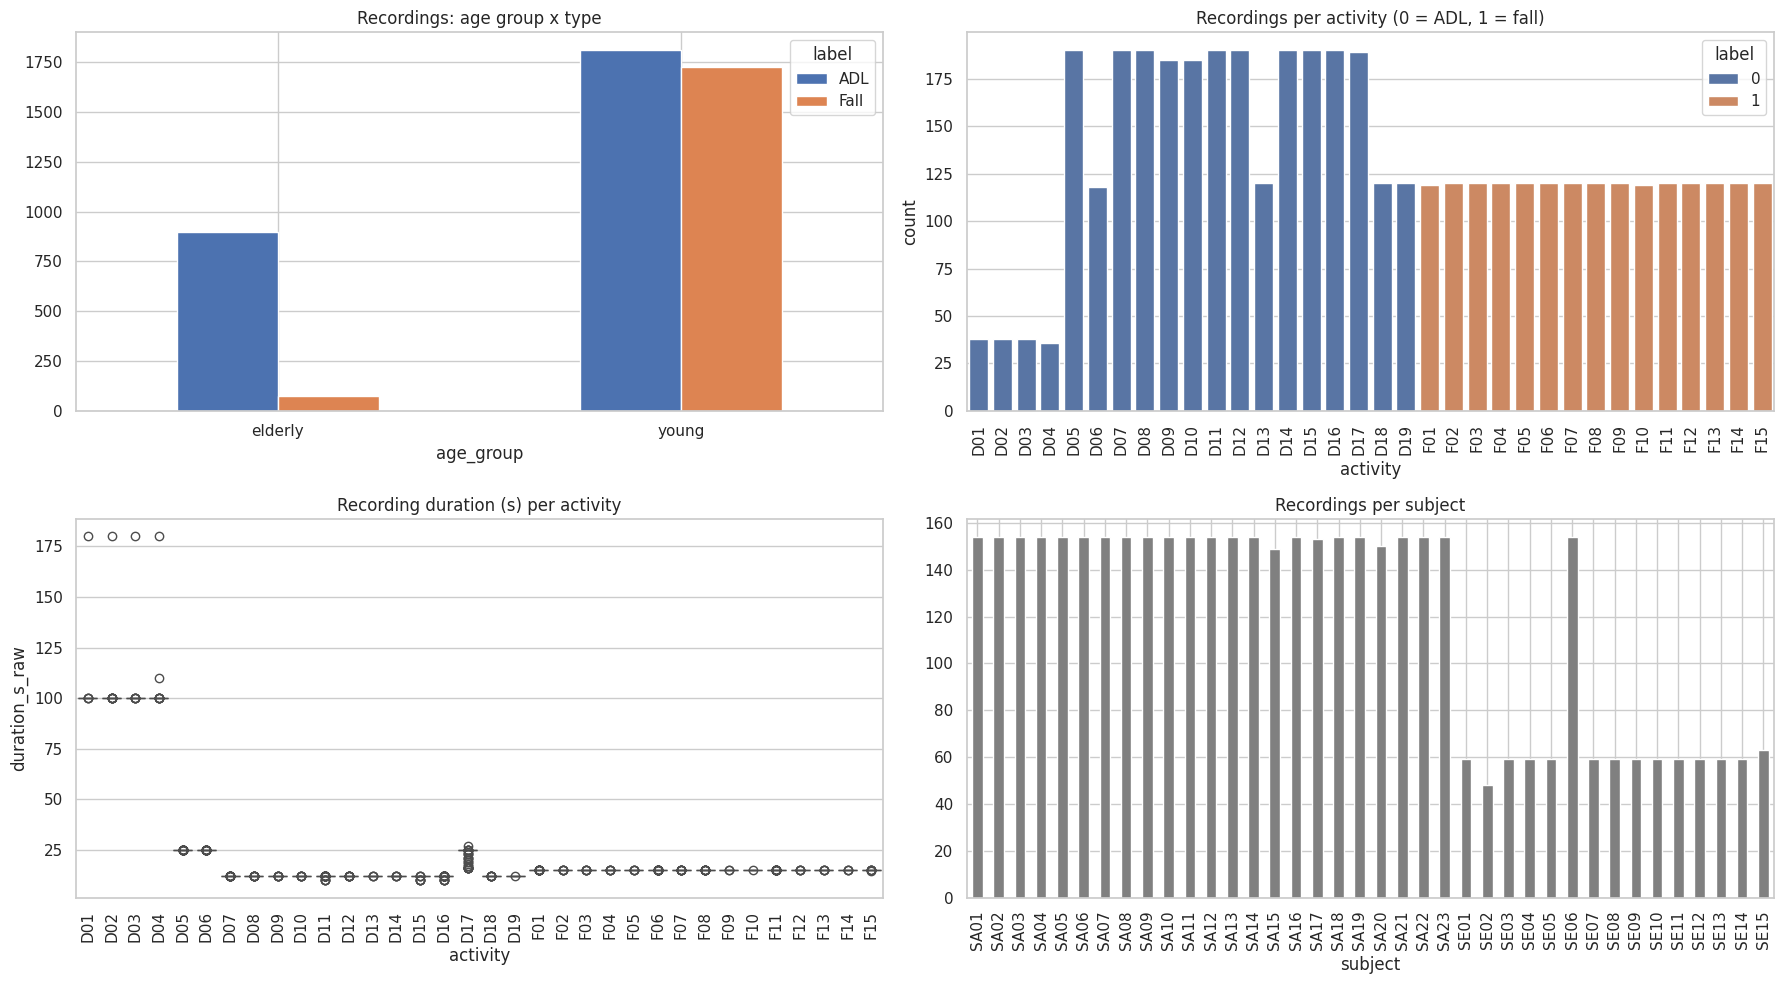

        count  mean   std   min   25%   50%   75%    max
label                                                   
0      2707.0  19.3  20.9  10.0  12.0  12.0  12.0  180.0
1      1798.0  15.0   0.0  14.5  15.0  15.0  15.0   15.0


In [11]:
def plot_composition(table):
    fig, axes = plt.subplots(2, 2, figsize=(18, 10))
    counts = table.groupby(['age_group', 'label']).size().unstack(fill_value=0)
    counts.rename(columns={0: 'ADL', 1: 'Fall'}).plot.bar(ax=axes[0, 0], rot=0)
    axes[0, 0].set_title('Recordings: age group x type')

    ordered = table.sort_values('activity')
    sns.countplot(data=ordered, x='activity', hue='label', dodge=False, ax=axes[0, 1])
    axes[0, 1].set_title('Recordings per activity (0 = ADL, 1 = fall)')
    sns.boxplot(data=ordered, x='activity', y='duration_s_raw', ax=axes[1, 0])
    axes[1, 0].set_title('Recording duration (s) per activity')
    table.groupby('subject').size().plot.bar(ax=axes[1, 1], color='gray')
    axes[1, 1].set_title('Recordings per subject')
    for ax in (axes[0, 1], axes[1, 0]):
        ax.tick_params(axis='x', rotation=90)
    plt.tight_layout()
    save_figure('eda_composition')
    plt.show()


plot_composition(recordings)
print(recordings.groupby('label').duration_s_raw.describe().round(1))

# study the signal

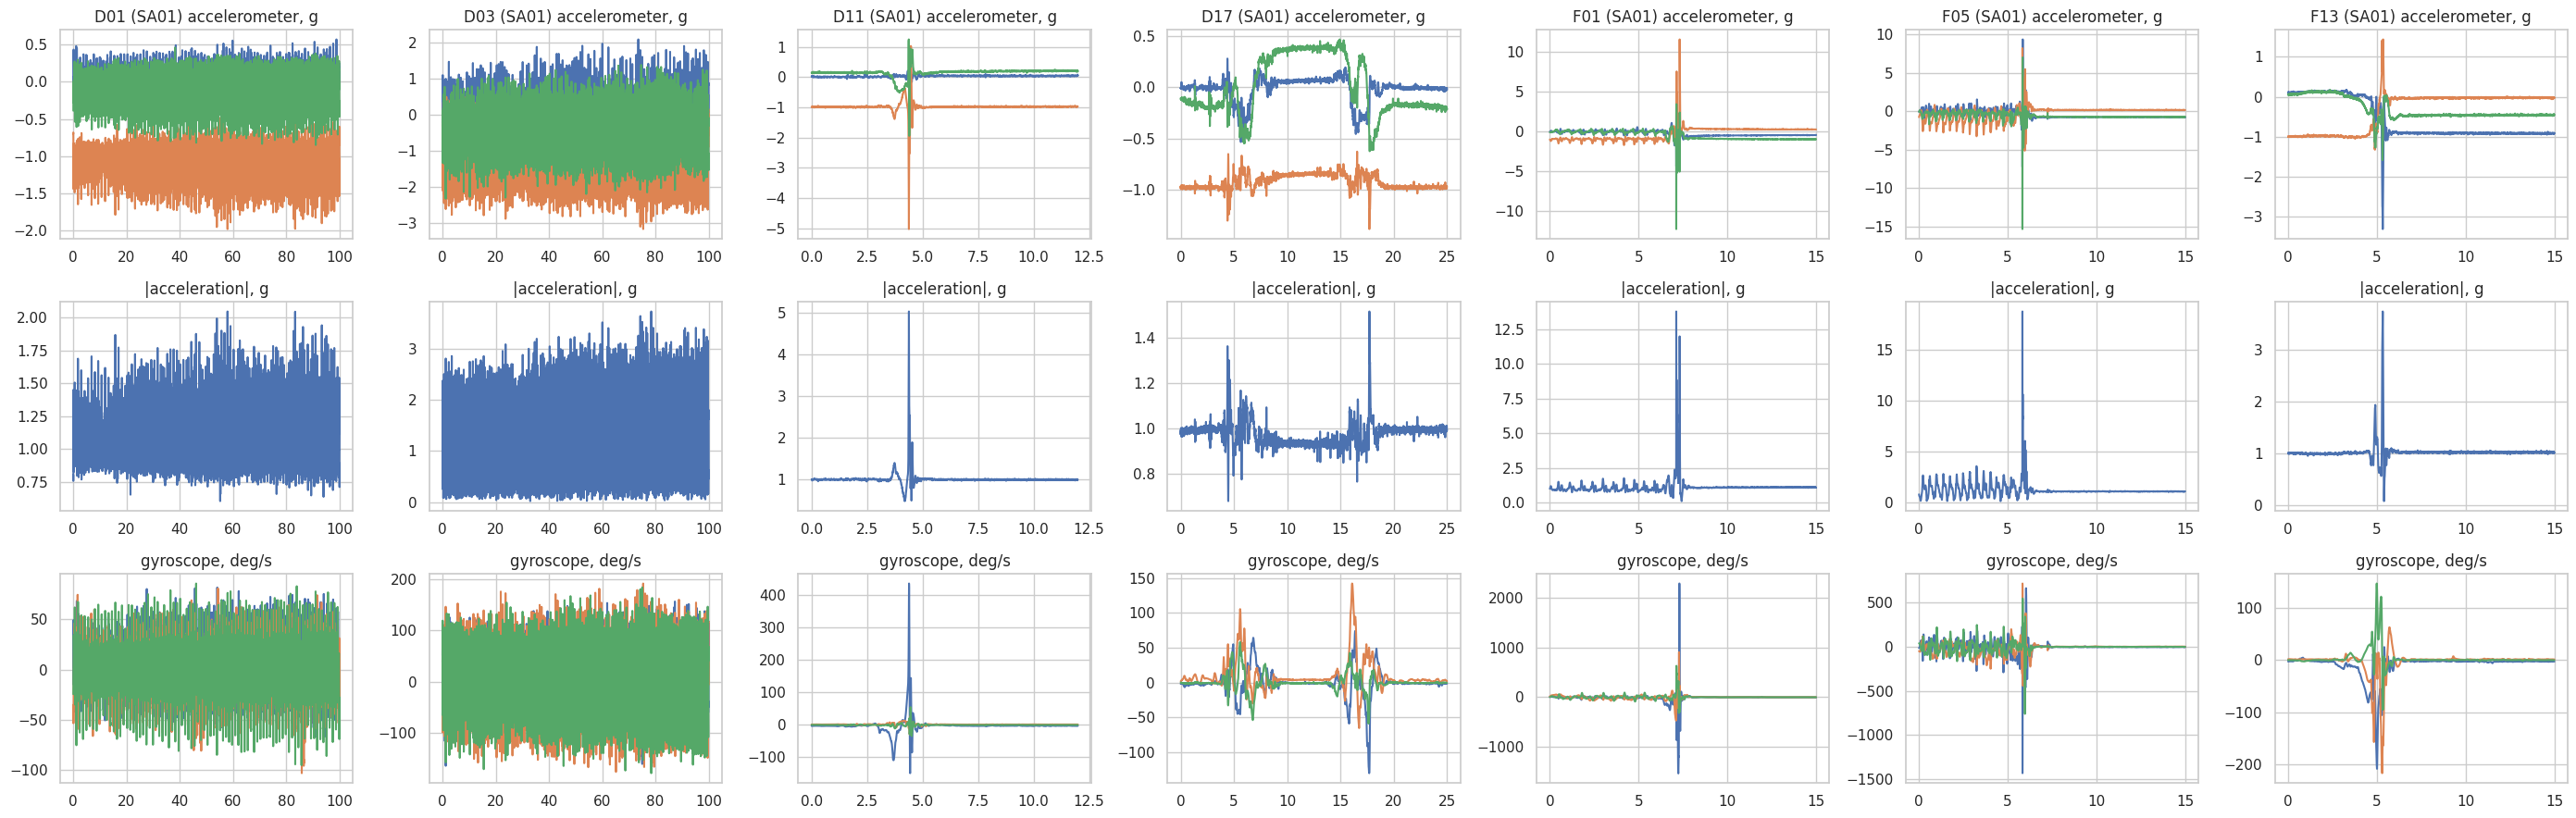

In [12]:
def plot_example_signals(table, signals, activity_codes):
    subject = table[table.label == 1].subject.value_counts().index[0]      # a subject who performed falls
    codes = [c for c in activity_codes if ((table.activity == c) & (table.subject == subject)).any()]
    fig, axes = plt.subplots(3, len(codes), figsize=(4 * len(codes), 9), squeeze=False)
    for col, code in enumerate(codes):
        row = table[(table.activity == code) & (table.subject == subject)].iloc[0]
        sig = signals[row.recording_id]
        time_s = np.arange(len(sig)) / RAW_FS_HZ
        axes[0, col].plot(time_s, sig[:, :3])
        axes[0, col].set_title(f'{code} ({subject}) accelerometer, g')
        axes[1, col].plot(time_s, np.linalg.norm(sig[:, :3], axis=1))
        axes[1, col].set_title('|acceleration|, g')
        axes[2, col].plot(time_s, sig[:, 3:])
        axes[2, col].set_title('gyroscope, deg/s')
    plt.tight_layout()
    save_figure('eda_examples')
    plt.show()


plot_example_signals(recordings, signals_200hz, ['D01', 'D03', 'D11', 'D17', 'F01', 'F05', 'F13'])

# Signal processing,Resample 200Hz to 50Hz

  0%|          | 0/4505 [00:00<?, ?it/s]

median fraction of the impact peak kept: 0.913


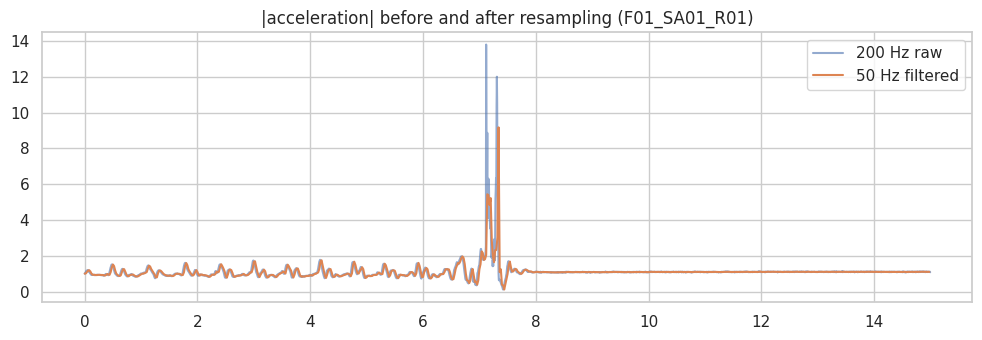

In [13]:
LOWPASS_SOS = signal.butter(LOWPASS_ORDER, LOWPASS_CUTOFF_HZ, btype='low', fs=RAW_FS_HZ, output='sos')
LOWPASS_ZI = signal.sosfilt_zi(LOWPASS_SOS)


def lowpass_and_decimate(sig_200hz):
    """Causal filter (the ESP32 can run the same one in real time), then decimate to 50 Hz."""
    filtered = np.empty(sig_200hz.shape, dtype=np.float64)
    for ch in range(sig_200hz.shape[1]):
        # start the filter state at the first sample to avoid a start-up transient
        filtered[:, ch], _ = signal.sosfilt(LOWPASS_SOS, sig_200hz[:, ch].astype(np.float64),
                                            zi=LOWPASS_ZI * sig_200hz[0, ch])
    return filtered[::DECIMATION].astype(np.float32)


signals_50hz = {rid: lowpass_and_decimate(sig) for rid, sig in tqdm(signals_200hz.items())}
recordings['n_samples_50hz'] = recordings.recording_id.map(lambda rid: len(signals_50hz[rid]))
recordings['duration_s'] = recordings.n_samples_50hz / MODEL_FS_HZ

# How much of the impact peak survives filtering + resampling? (thresholds must be set on the filtered signal)
fall_ids = recordings[recordings.label == 1].recording_id.iloc[:300]
peak_retained = [acc_magnitude(signals_50hz[r]).max() / acc_magnitude(signals_200hz[r]).max() for r in fall_ids]
print('median fraction of the impact peak kept:', round(float(np.median(peak_retained)), 3))

example_id = fall_ids.iloc[0]
plt.figure(figsize=(12, 3.5))
plt.plot(np.arange(len(signals_200hz[example_id])) / RAW_FS_HZ, acc_magnitude(signals_200hz[example_id]), alpha=.6, label='200 Hz raw')
plt.plot(np.arange(len(signals_50hz[example_id])) / MODEL_FS_HZ, acc_magnitude(signals_50hz[example_id]), label='50 Hz filtered')
plt.legend()
plt.title(f'|acceleration| before and after resampling ({example_id})')
save_figure('eda_resample')
plt.show()

# Impact of location per recording

fall recordings                        : 1798
impact in the first second             : 0
less than 1 s of data after the impact : 0
fall peak below 1.5 g (suspicious)     : 0
ADL peaks above the 25th percentile of fall peaks: 9.9 %
fall recordings with < 6 s after impact: 157 (too short to test a 5 s stillness rule)


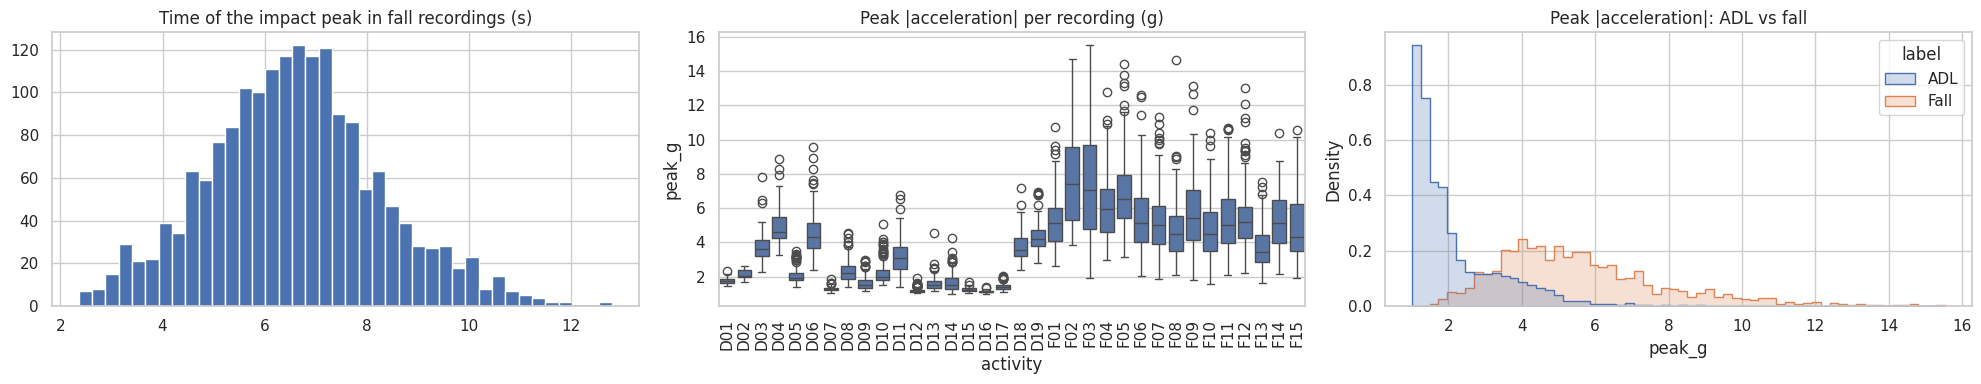

In [14]:
def add_impact_columns(table, signals):
    peak_index = [int(acc_magnitude(signals[rid]).argmax()) for rid in table.recording_id]
    table['peak_index'] = peak_index
    table['peak_g'] = [float(acc_magnitude(signals[rid])[i]) for rid, i in zip(table.recording_id, peak_index)]
    table['peak_time_s'] = table.peak_index / MODEL_FS_HZ
    table['post_impact_s'] = (table.n_samples_50hz - table.peak_index) / MODEL_FS_HZ
    table['impact_index'] = np.where(table.label == 1, table.peak_index, -1)       # -1 = no impact for ADLs
    return table


recordings = add_impact_columns(recordings, signals_50hz)
fall_rows = recordings[recordings.label == 1]
adl_rows = recordings[recordings.label == 0]
print('fall recordings                        :', len(fall_rows))
print('impact in the first second             :', int((fall_rows.peak_time_s < 1).sum()))
print('less than 1 s of data after the impact :', int((fall_rows.post_impact_s < 1).sum()))
print('fall peak below 1.5 g (suspicious)     :', int((fall_rows.peak_g < 1.5).sum()))
print('ADL peaks above the 25th percentile of fall peaks:',
      round(100 * float((adl_rows.peak_g > fall_rows.peak_g.quantile(.25)).mean()), 1), '%')
print('fall recordings with < 6 s after impact:', int((fall_rows.post_impact_s < 6).sum()),
      '(too short to test a 5 s stillness rule)')

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
axes[0].hist(fall_rows.peak_time_s, bins=40)
axes[0].set_title('Time of the impact peak in fall recordings (s)')
sns.boxplot(data=recordings.sort_values('activity'), x='activity', y='peak_g', ax=axes[1])
axes[1].tick_params(axis='x', rotation=90)
axes[1].set_title('Peak |acceleration| per recording (g)')
sns.histplot(data=recordings, x='peak_g', hue=recordings.label.map({0: 'ADL', 1: 'Fall'}), bins=60,
             element='step', stat='density', common_norm=False, ax=axes[2])
axes[2].set_title('Peak |acceleration|: ADL vs fall')
plt.tight_layout()
save_figure('eda_peaks')
plt.show()

# Split, windows and verification

In [15]:
# Subject wise splitting

def split_subjects(subjects, test_fraction=0.20, val_fraction=0.15, rng=None):
    subjects = sorted(subjects)
    rng.shuffle(subjects)
    n_test = max(1, round(test_fraction * len(subjects)))
    n_val = max(1, round(val_fraction * len(subjects)))
    return dict(test=subjects[:n_test], val=subjects[n_test:n_test + n_val], train=subjects[n_test + n_val:])


def make_subject_split(table):
    """Split fall subjects and no-fall subjects separately so every split contains falls."""
    rng = np.random.RandomState(SEED)
    fall_subjects = sorted(table.loc[table.label == 1, 'subject'].unique())
    no_fall_subjects = sorted(set(table.subject) - set(fall_subjects))
    with_falls = split_subjects(fall_subjects, rng=rng)
    without_falls = split_subjects(no_fall_subjects, rng=rng)
    return {name: sorted(with_falls[name] + without_falls[name]) for name in SPLIT_NAMES}


SUBJECT_SPLITS = make_subject_split(recordings)
subject_to_split = {s: name for name, subs in SUBJECT_SPLITS.items() for s in subs}
recordings['split'] = recordings.subject.map(subject_to_split)

assert recordings.split.notna().all()
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert not set(SUBJECT_SPLITS[a]) & set(SUBJECT_SPLITS[b]), f'subjects shared between {a} and {b}'
for name in SPLIT_NAMES:
    assert (recordings[recordings.split == name].label == 1).any(), f'{name} has no falls'

print(recordings.groupby('split').agg(subjects=('subject', 'nunique'), files=('recording_id', 'size'),
                                      fall_files=('label', 'sum')))
for name, subs in SUBJECT_SPLITS.items():
    print(name, subs)

       subjects  files  fall_files
split                             
test          8    939         375
train        24   2832        1123
val           6    734         300
train ['SA03', 'SA04', 'SA05', 'SA06', 'SA07', 'SA08', 'SA11', 'SA13', 'SA15', 'SA16', 'SA18', 'SA20', 'SA21', 'SA23', 'SE01', 'SE03', 'SE04', 'SE06', 'SE07', 'SE08', 'SE09', 'SE10', 'SE11', 'SE13']
val ['SA02', 'SA10', 'SA14', 'SA22', 'SE12', 'SE14']
test ['SA01', 'SA09', 'SA12', 'SA17', 'SA19', 'SE02', 'SE05', 'SE15']


# Windows with impact based labels

In [16]:
def make_windows_for_recording(sig, label, impact_index):
    """Cut one recording into windows. ADL windows are all kept; a fall window is kept only if the
    impact sits inside it (positions IMPACT_MIN_POS..IMPACT_MAX_POS). Walking before the fall and
    lying after it never get the fall label."""
    windows = sliding_window_view(sig, WINDOW_LEN, axis=0)[::WINDOW_STRIDE].transpose(0, 2, 1)   # (n, 100, 6)
    starts = np.arange(len(windows)) * WINDOW_STRIDE
    if label == 0:
        role = np.array(['adl'] * len(starts))
        impact_pos = np.full(len(starts), -1)
    else:
        impact_pos = impact_index - starts                                  # where the impact sits in each window
        inside = (impact_pos >= 0) & (impact_pos < WINDOW_LEN)
        good = inside & (impact_pos >= IMPACT_MIN_POS) & (impact_pos < IMPACT_MAX_POS)
        role = np.where(good, 'fall_impact',
                        np.where(inside, 'fall_border', np.where(impact_pos >= WINDOW_LEN, 'fall_before', 'fall_after')))
    keep = np.isin(role, ['adl', 'fall_impact'])
    info = pd.DataFrame(dict(window_start=starts[keep], role=role[keep], impact_pos=impact_pos[keep]))
    info['label'] = (info.role == 'fall_impact').astype(int)
    return np.ascontiguousarray(windows[keep]), info, Counter(map(str, role[~keep]))


def build_window_dataset(table, signals):
    window_chunks, info_chunks, dropped = [], [], Counter()
    for rec in tqdm(table.itertuples(index=False), total=len(table)):
        sig = signals[rec.recording_id]
        if len(sig) < WINDOW_LEN:
            continue
        windows, info, dropped_roles = make_windows_for_recording(sig, rec.label, rec.impact_index)
        dropped.update(dropped_roles)
        if len(info) == 0:
            continue
        info['recording_id'], info['subject'], info['trial'] = rec.recording_id, rec.subject, rec.trial
        info['activity'], info['split'] = rec.activity, rec.split
        window_chunks.append(windows)
        info_chunks.append(info)
    return np.concatenate(window_chunks).astype(np.float32), pd.concat(info_chunks, ignore_index=True), dropped


windows, window_meta, dropped_windows = build_window_dataset(recordings, signals_50hz)
window_labels = window_meta.label.values.astype(np.int32)

print('windows:', windows.shape, '| fall windows:', int(window_labels.sum()), '| ADL windows:', int((window_labels == 0).sum()))
print('dropped from fall recordings (not used):', dict(dropped_windows))
falls_per_recording = window_meta[window_meta.label == 1].groupby('recording_id').size()
print('fall windows per fall recording:', falls_per_recording.describe()[['min', 'mean', 'max']].round(2).to_dict())
print('fall recordings with no impact window :', len(set(recordings[recordings.label == 1].recording_id) - set(falls_per_recording.index)))

  0%|          | 0/4505 [00:00<?, ?it/s]

windows: (51760, 100, 6) | fall windows: 2152 | ADL windows: 49608
dropped from fall recordings (not used): {'fall_before': 9186, 'fall_border': 1444, 'fall_after': 12385}
fall windows per fall recording: {'min': 1.0, 'mean': 1.2, 'max': 2.0}
fall recordings with no impact window : 0


# verify the processed data

label    ADL  Fall  fall_%  subjects
split                               
test   10189   454    4.27         8
train  31499  1340    4.08        24
val     7920   358    4.32         6


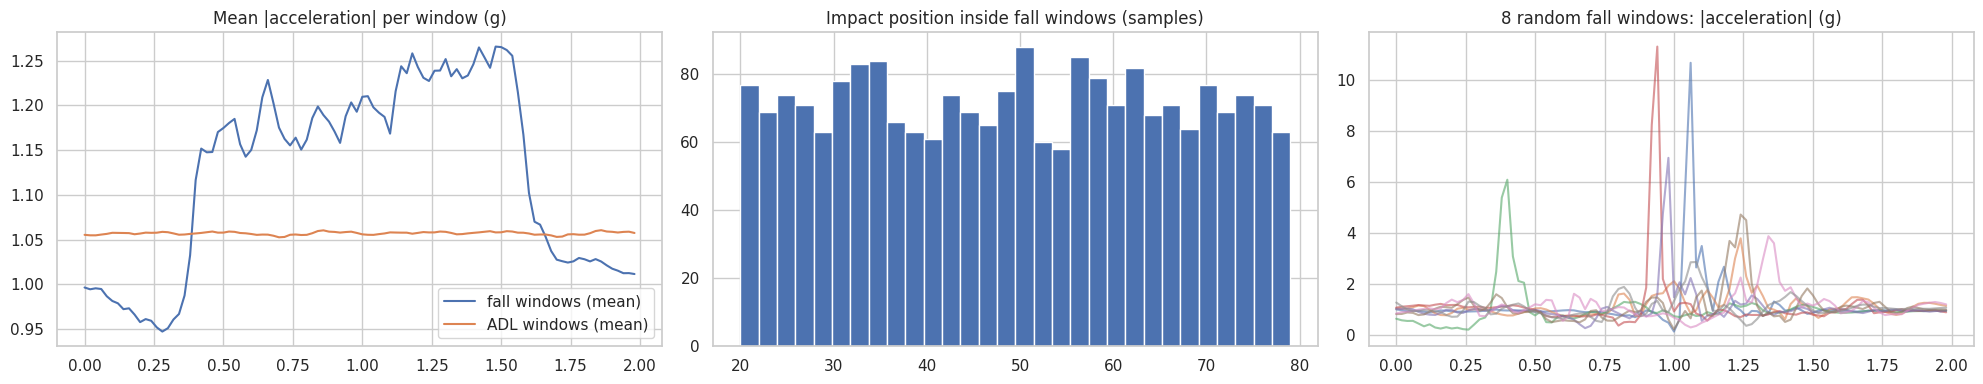

median peak |acceleration| in fall windows: 5.18 g


In [17]:
def verify_dataset(windows, window_meta, window_labels):
    assert windows.shape[1:] == (WINDOW_LEN, 6)
    assert np.isfinite(windows).all()
    assert len(windows) == len(window_meta) == len(window_labels)
    subjects = {name: set(window_meta.loc[window_meta.split == name, 'subject']) for name in SPLIT_NAMES}
    assert not (subjects['train'] & subjects['val']) and not (subjects['train'] & subjects['test']) \
        and not (subjects['val'] & subjects['test']), 'a subject appears in two splits'
    table = window_meta.groupby(['split', 'label']).size().unstack(fill_value=0).rename(columns={0: 'ADL', 1: 'Fall'})
    table['fall_%'] = (100 * table.Fall / (table.ADL + table.Fall)).round(2)
    table['subjects'] = [len(subjects[s]) for s in table.index]
    assert (table.Fall > 0).all(), 'a split has no fall windows'
    return table


print(verify_dataset(windows, window_meta, window_labels))

window_acc_mag = np.linalg.norm(windows[:, :, :3], axis=2)
time_s = np.arange(WINDOW_LEN) / MODEL_FS_HZ
fig, axes = plt.subplots(1, 3, figsize=(20, 4))
axes[0].plot(time_s, window_acc_mag[window_labels == 1].mean(0), label='fall windows (mean)')
axes[0].plot(time_s, window_acc_mag[window_labels == 0].mean(0), label='ADL windows (mean)')
axes[0].legend()
axes[0].set_title('Mean |acceleration| per window (g)')
axes[1].hist(window_meta.loc[window_labels == 1, 'impact_pos'], bins=30)
axes[1].set_title('Impact position inside fall windows (samples)')
for i in np.random.choice(np.where(window_labels == 1)[0], 8, replace=False):
    axes[2].plot(time_s, window_acc_mag[i], alpha=.6)
axes[2].set_title('8 random fall windows: |acceleration| (g)')
plt.tight_layout()
save_figure('verify_windows')
plt.show()
print('median peak |acceleration| in fall windows:', round(float(np.median(window_acc_mag[window_labels == 1].max(1))), 2), 'g')

# save the processed dataset

In [18]:
np.savez_compressed(f'{OUTPUT_DIR}/windows_50hz_2s.npz', windows=windows, labels=window_labels,
                    subject=window_meta.subject.values.astype('U8'), activity=window_meta.activity.values.astype('U4'),
                    split=window_meta.split.values.astype('U5'), recording_id=window_meta.recording_id.values.astype('U20'))
window_meta.to_csv(f'{OUTPUT_DIR}/window_meta.csv', index=False)
recordings.drop(columns=['path']).to_csv(f'{OUTPUT_DIR}/recordings_meta.csv', index=False)
dump(signals_50hz, f'{OUTPUT_DIR}/signals_50hz.joblib', compress=3)         # needed later for the replay cells

dataset_config = dict(seed=SEED, raw_fs_hz=RAW_FS_HZ, model_fs_hz=MODEL_FS_HZ, window_len=WINDOW_LEN,
                      window_stride=WINDOW_STRIDE, impact_range=[IMPACT_MIN_POS, IMPACT_MAX_POS],
                      lowpass_cutoff_hz=LOWPASS_CUTOFF_HZ, lowpass_order=LOWPASS_ORDER, lowpass_sos=LOWPASS_SOS.tolist(),
                      gyro_scale=GYRO_SCALE, gyro_dps_per_count=GYRO_DPS_PER_COUNT, subject_splits=SUBJECT_SPLITS)
json.dump(dataset_config, open(f'{OUTPUT_DIR}/dataset_config.json', 'w'), indent=2)
print('saved:', sorted(os.listdir(OUTPUT_DIR)))

saved: ['cnn_fall.keras', 'cnn_fall_int8.tflite', 'dataset_config.json', 'decision_tree.joblib', 'features.csv', 'plots', 'preprocessing.json', 'random_forest.joblib', 'recordings_meta.csv', 'replay_test_results.csv', 'sentinel_params.h', 'signals_50hz.joblib', 'test_metrics.csv', 'window_meta.csv', 'windows_50hz_2s.npz']


# Feature Engineering

In [19]:
def extract_features(windows, fs=MODEL_FS_HZ):
    """One row of features per window. No FFT, skew or kurtosis: keep the firmware simple."""
    n_samples = windows.shape[1]
    acc = windows[:, :, :3].astype(np.float64)
    gyro = windows[:, :, 3:].astype(np.float64)
    acc_mag = np.linalg.norm(acc, axis=2)
    gyro_mag = np.linalg.norm(gyro, axis=2)
    feats = {}

    def add_basic_stats(prefix, values):
        feats[f'{prefix}_mean'] = values.mean(1)
        feats[f'{prefix}_std'] = values.std(1)
        feats[f'{prefix}_max'] = values.max(1)
        feats[f'{prefix}_min'] = values.min(1)
        feats[f'{prefix}_range'] = feats[f'{prefix}_max'] - feats[f'{prefix}_min']
        feats[f'{prefix}_rms'] = np.sqrt((values ** 2).mean(1))

    add_basic_stats('acc_mag', acc_mag)
    add_basic_stats('gyro_mag', gyro_mag)

    # jerk = how fast the magnitude changes
    acc_jerk = np.diff(acc_mag, axis=1) * fs
    gyro_jerk = np.diff(gyro_mag, axis=1) * fs
    feats['acc_jerk_max'] = np.abs(acc_jerk).max(1)
    feats['acc_jerk_rms'] = np.sqrt((acc_jerk ** 2).mean(1))
    feats['gyro_jerk_max'] = np.abs(gyro_jerk).max(1)

    for i, axis_name in enumerate('xyz'):
        feats[f'acc_{axis_name}_std'] = acc[:, :, i].std(1)
        feats[f'gyro_{axis_name}_std'] = gyro[:, :, i].std(1)
    feats['acc_sma'] = np.abs(acc).sum(2).mean(1)             # signal magnitude area
    feats['gyro_sma'] = np.abs(gyro).sum(2).mean(1)

    # around the impact: dip before the peak (free-fall), calm after it (stillness)
    positions = np.arange(n_samples)[None, :]
    peak = acc_mag.argmax(1)[:, None]
    feats['peak_position'] = peak[:, 0] / n_samples

    def masked_stat(mask, stat_fn, fallback):
        values = stat_fn(np.where(mask, acc_mag, np.nan), axis=1)
        return np.where(np.isnan(values), fallback, values)

    just_before_peak = (positions < peak) & (positions >= peak - fs // 2)
    feats['pre_peak_min'] = masked_stat(just_before_peak, np.nanmin, acc_mag.mean(1))
    feats['pre_peak_mean'] = masked_stat(positions < peak, np.nanmean, acc_mag.mean(1))
    feats['post_peak_mean'] = masked_stat(positions > peak, np.nanmean, acc_mag.mean(1))
    feats['post_peak_std'] = masked_stat(positions > peak, np.nanstd, 0.0)
    feats['peak_minus_pre_min'] = feats['acc_mag_max'] - feats['pre_peak_min']

    # orientation change between the first and the last half second of the window
    half_second = fs // 2
    feats['tilt_change_deg'] = tilt_angle_deg(acc[:, :half_second].mean(1), acc[:, -half_second:].mean(1))

    return pd.DataFrame(feats).replace([np.inf, -np.inf], np.nan).fillna(0).astype(np.float32)


start_time = time.time()
features = extract_features(windows)
FEATURE_COLUMNS = list(features.columns)
print(features.shape, f'{time.time() - start_time:.1f} s', '| NaNs:', int(features.isna().sum().sum()))
features.to_csv(f'{OUTPUT_DIR}/features.csv', index=False)

(51760, 30) 1.6 s | NaNs: 0


# feature EDA

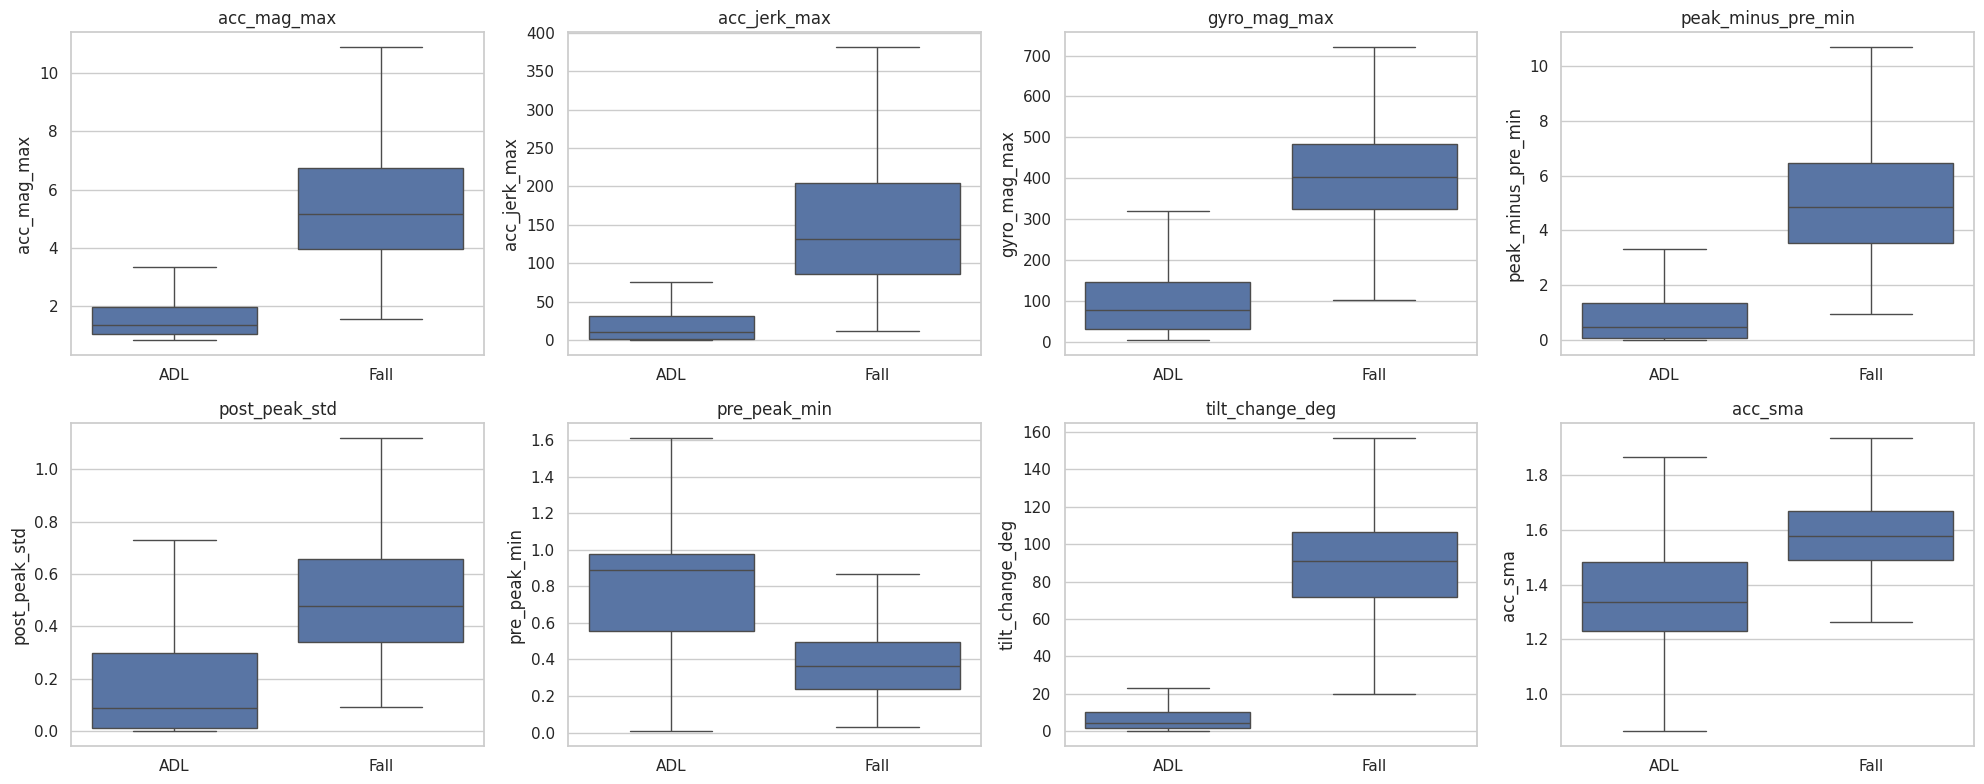

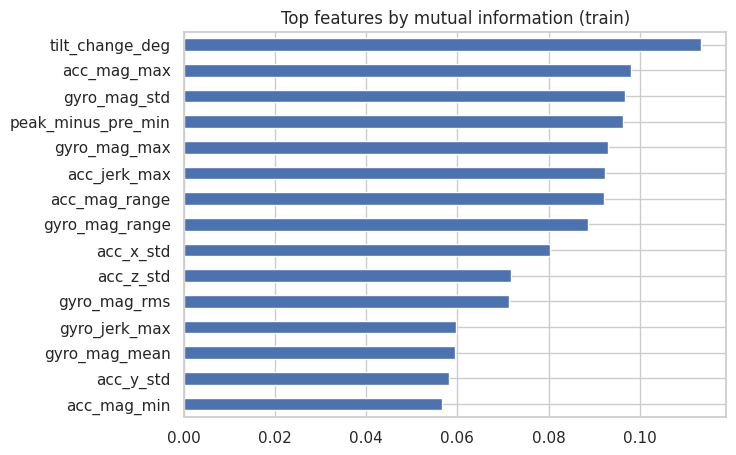

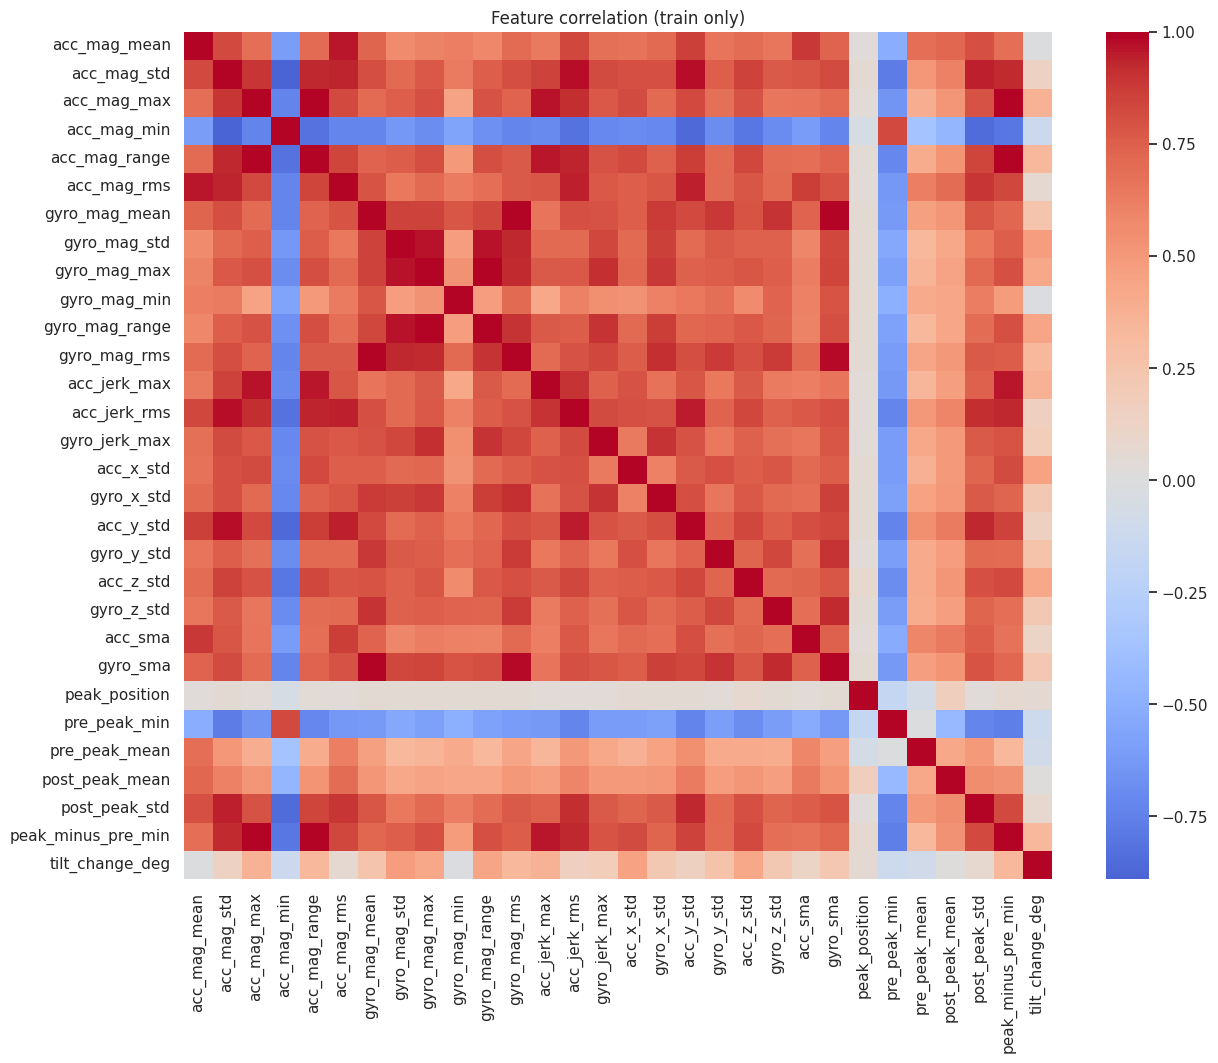

In [20]:
from sklearn.feature_selection import mutual_info_classif

train_mask = (window_meta.split.values == 'train')
label_names = pd.Series(window_labels).map({0: 'ADL', 1: 'Fall'}).values
features_to_plot = ['acc_mag_max', 'acc_jerk_max', 'gyro_mag_max', 'peak_minus_pre_min',
                    'post_peak_std', 'pre_peak_min', 'tilt_change_deg', 'acc_sma']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, name in zip(axes.ravel(), features_to_plot):
    sns.boxplot(x=label_names[train_mask], y=features.loc[train_mask, name], ax=ax, showfliers=False)
    ax.set_title(name)
plt.tight_layout()
save_figure('eda_features_box')
plt.show()

sample_rows = np.random.RandomState(SEED).choice(np.where(train_mask)[0], min(30000, train_mask.sum()), replace=False)
mutual_info = pd.Series(mutual_info_classif(features.iloc[sample_rows], window_labels[sample_rows], random_state=SEED),
                        index=features.columns).sort_values()
mutual_info.tail(15).plot.barh(figsize=(7, 5), title='Top features by mutual information (train)')
save_figure('eda_features_mi')
plt.show()

plt.figure(figsize=(14, 11))
sns.heatmap(features.loc[train_mask].corr(), cmap='coolwarm', center=0)
plt.title('Feature correlation (train only)')
save_figure('eda_features_corr')
plt.show()

# Train and Tune the Decision Tree and Random Forest

DecisionTree: best validation PR-AUC 0.9877 with {'max_depth': 8, 'min_samples_leaf': 50}
RandomForest: best validation PR-AUC 0.9954 with {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 30}
thresholds: {'DecisionTree': 0.8940488113436289, 'RandomForest': 0.5539444994542773}
random forest nodes in total: 2794 (check against your flash budget)

Decision tree rules:
 |--- tilt_change_deg <= 41.00
|   |--- acc_mag_max <= 4.19
|   |   |--- gyro_mag_std <= 65.49
|   |   |   |--- gyro_mag_std <= 52.86
|   |   |   |   |--- tilt_change_deg <= 28.48
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- tilt_change_deg >  28.48
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- gyro_mag_std >  52.86
|   |   |   |   |--- gyro_mag_max <= 238.21
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- gyro_mag_max >  238.21
|   |   |   |   |   |--- class: 0
|   |   |--- gyro_mag_std >  65.49
|   |   |   |--- ti

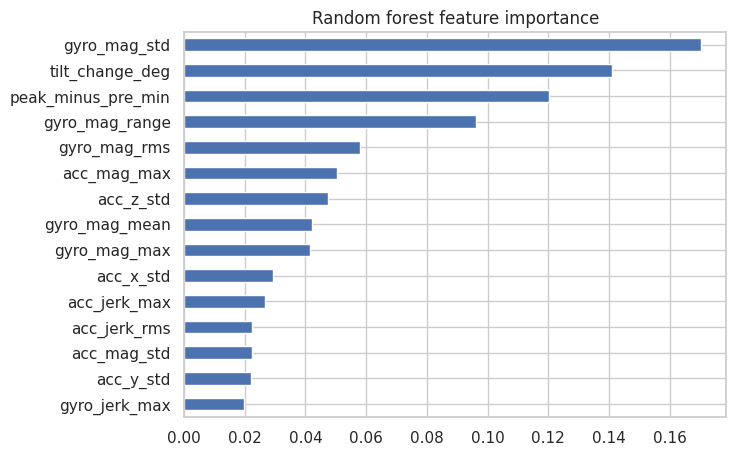

In [21]:

from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             average_precision_score, roc_auc_score, precision_recall_curve, roc_curve)

split_indices = {name: np.where(window_meta.split.values == name)[0] for name in SPLIT_NAMES}
features_by_split = {name: features.iloc[idx].values for name, idx in split_indices.items()}
labels_by_split = {name: window_labels[idx] for name, idx in split_indices.items()}


def best_f_beta_threshold(labels, probs, beta=2.0):
    """Threshold that maximises F-beta on the validation set (beta = 2 favours recall over precision)."""
    precision, recall, thresholds_ = precision_recall_curve(labels, probs)
    f_beta = (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall + 1e-12)
    return float(thresholds_[np.nanargmax(f_beta[:-1])])


def tune_model(make_model, param_grid, name):
    """Try every parameter combination, keep the one with the best validation PR-AUC."""
    best_score, best_params, best_model = -1, None, None
    for params in ParameterGrid(param_grid):
        model = make_model(**params).fit(features_by_split['train'], labels_by_split['train'])
        score = average_precision_score(labels_by_split['val'], model.predict_proba(features_by_split['val'])[:, 1])
        if score > best_score:
            best_score, best_params, best_model = score, params, model
    print(f'{name}: best validation PR-AUC {best_score:.4f} with {best_params}')
    return best_params, best_model


tree_params, tree_model = tune_model(
    lambda **p: DecisionTreeClassifier(class_weight='balanced', random_state=SEED, **p),
    dict(max_depth=[3, 4, 5, 6, 8], min_samples_leaf=[5, 20, 50]), 'DecisionTree')

forest_params, forest_model = tune_model(      # deployment limits: 10-30 trees, depth <= 8
    lambda **p: RandomForestClassifier(n_jobs=-1, class_weight='balanced_subsample', random_state=SEED, **p),
    dict(n_estimators=[10, 20, 30], max_depth=[4, 6, 8], min_samples_leaf=[5, 20], max_features=['sqrt']), 'RandomForest')

thresholds = {   # decision thresholds are chosen on validation subjects only
    'DecisionTree': best_f_beta_threshold(labels_by_split['val'], tree_model.predict_proba(features_by_split['val'])[:, 1]),
    'RandomForest': best_f_beta_threshold(labels_by_split['val'], forest_model.predict_proba(features_by_split['val'])[:, 1]),
}
print('thresholds:', thresholds)
print('random forest nodes in total:', sum(t.tree_.node_count for t in forest_model.estimators_), '(check against your flash budget)')
print('\nDecision tree rules:\n', export_text(tree_model, feature_names=FEATURE_COLUMNS, max_depth=4))

pd.Series(forest_model.feature_importances_, index=FEATURE_COLUMNS).sort_values().tail(15).plot.barh(
    figsize=(7, 5), title='Random forest feature importance')
save_figure('rf_importance')
plt.show()

# Evaluate the tree models on test subject

              threshold     TP    FP    FN       TN  precision  recall  fall_F1  macro_F1  balanced_accuracy  PR_AUC  ROC_AUC
DecisionTree      0.894  438.0  32.0  16.0  10157.0     0.9319  0.9648   0.9481    0.9728             0.9808  0.9815   0.9952
RandomForest      0.554  444.0  26.0  10.0  10163.0     0.9447  0.9780   0.9610    0.9796             0.9877  0.9947   0.9997


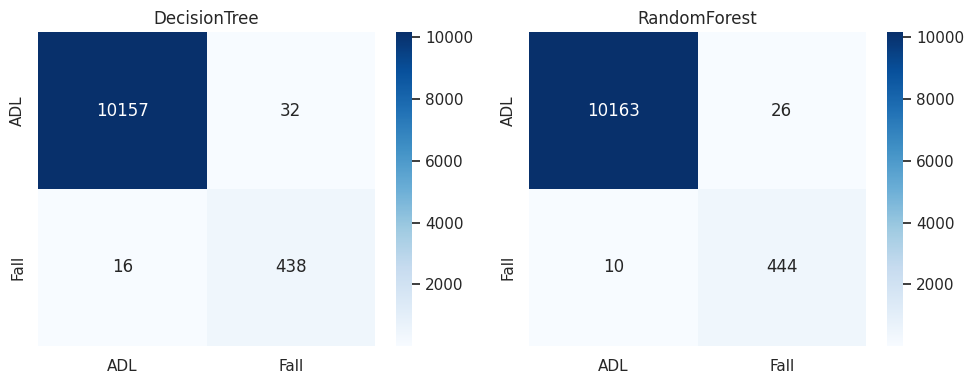

In [22]:
def evaluate_scores(labels, probs, threshold):
    predicted = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    return dict(threshold=round(threshold, 3), TP=tp, FP=fp, FN=fn, TN=tn,
                precision=precision_score(labels, predicted, zero_division=0), recall=recall_score(labels, predicted),
                fall_F1=f1_score(labels, predicted), macro_F1=f1_score(labels, predicted, average='macro'),
                balanced_accuracy=balanced_accuracy_score(labels, predicted),
                PR_AUC=average_precision_score(labels, probs), ROC_AUC=roc_auc_score(labels, probs))


window_probs_test = {
    'DecisionTree': tree_model.predict_proba(features_by_split['test'])[:, 1],
    'RandomForest': forest_model.predict_proba(features_by_split['test'])[:, 1],
}
print(pd.DataFrame({name: evaluate_scores(labels_by_split['test'], probs, thresholds[name])
                    for name, probs in window_probs_test.items()}).T.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, probs) in zip(axes, window_probs_test.items()):
    matrix = confusion_matrix(labels_by_split['test'], (probs >= thresholds[name]).astype(int))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=['ADL', 'Fall'], yticklabels=['ADL', 'Fall'])
    ax.set_title(name)
plt.tight_layout()
save_figure('confusion_trees')
plt.show()

# Train 1-D CNN

In [23]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(SEED)

norm_mean = windows[split_indices['train']].mean(axis=(0, 1))
norm_std = windows[split_indices['train']].std(axis=(0, 1)) + 1e-6


def normalize_windows(raw_windows):
    return ((raw_windows - norm_mean) / norm_std).astype(np.float32)


def build_cnn_model(filters=(16, 32, 64)):
    inputs = keras.Input((WINDOW_LEN, 6))
    x = inputs
    for n_filters in filters:
        x = layers.Conv1D(n_filters, 5, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(inputs, layers.Dense(1, activation='sigmoid')(x))


def make_augmented_dataset(raw_windows, labels, batch_size=256, max_rotation_deg=15):
    """Random sensor variation in physical units, then normalisation. This narrows the gap between the
    SisFall sensors/mounting and your MPU6050: small rotation, gain/offset errors, gyro bias, noise."""
    mean_t, std_t = tf.constant(norm_mean, tf.float32), tf.constant(norm_std, tf.float32)

    def random_rotation(angles):
        cx, cy, cz = tf.unstack(tf.cos(angles))
        sx, sy, sz = tf.unstack(tf.sin(angles))
        rot_x = tf.stack([[1., 0., 0.], [0., cx, -sx], [0., sx, cx]])
        rot_y = tf.stack([[cy, 0., sy], [0., 1., 0.], [-sy, 0., cy]])
        rot_z = tf.stack([[cz, -sz, 0.], [sz, cz, 0.], [0., 0., 1.]])
        return rot_z @ rot_y @ rot_x

    def augment(window, label):
        angles = tf.random.uniform([3], -max_rotation_deg, max_rotation_deg) * np.pi / 180.0
        rotation_t = tf.transpose(random_rotation(angles))
        acc, gyro = window[:, :3] @ rotation_t, window[:, 3:] @ rotation_t          # same rotation for both sensors
        acc = acc * tf.random.uniform([], 0.95, 1.05) + tf.random.uniform([3], -0.05, 0.05)    # gain and offset error
        gyro = gyro * tf.random.uniform([], 0.85, 1.15) + tf.random.uniform([3], -5., 5.)      # gain error and bias
        noisy = tf.concat([acc, gyro], axis=1) + tf.random.normal(tf.shape(window), stddev=0.01)
        return (noisy - mean_t) / std_t, label

    dataset = tf.data.Dataset.from_tensor_slices((raw_windows.astype(np.float32), labels.astype(np.float32)))
    return (dataset.shuffle(20000, seed=SEED).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(batch_size).prefetch(tf.data.AUTOTUNE))


cnn_model = build_cnn_model()
cnn_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(curve='PR', name='pr_auc'), keras.metrics.Recall(name='recall')])
print('parameters:', cnn_model.count_params())

class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=labels_by_split['train'])
train_dataset = make_augmented_dataset(windows[split_indices['train']], labels_by_split['train'])
val_inputs = normalize_windows(windows[split_indices['val']])

history = cnn_model.fit(
    train_dataset, validation_data=(val_inputs, labels_by_split['val'].astype(np.float32)),
    epochs=60, class_weight={0: class_weights[0], 1: class_weights[1]}, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=8, restore_best_weights=True),
               keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)])

thresholds['CNN'] = best_f_beta_threshold(labels_by_split['val'], cnn_model.predict(val_inputs, batch_size=2048, verbose=0).ravel())
window_probs_test['CNN'] = cnn_model.predict(normalize_windows(windows[split_indices['test']]), batch_size=2048, verbose=0).ravel()
print('CNN threshold (validation):', round(thresholds['CNN'], 3))

parameters: 15841
Epoch 1/60
129/129 - 27s - 213ms/step - loss: 0.1829 - pr_auc: 0.8146 - recall: 0.9836 - val_loss: 0.0831 - val_pr_auc: 0.9932 - val_recall: 0.9916 - learning_rate: 0.0010
Epoch 2/60
129/129 - 7s - 53ms/step - loss: 0.0498 - pr_auc: 0.9615 - recall: 0.9873 - val_loss: 0.0248 - val_pr_auc: 0.9956 - val_recall: 0.9916 - learning_rate: 0.0010
Epoch 3/60
129/129 - 7s - 52ms/step - loss: 0.0363 - pr_auc: 0.9678 - recall: 0.9910 - val_loss: 0.0107 - val_pr_auc: 0.9944 - val_recall: 0.9916 - learning_rate: 0.0010
Epoch 4/60
129/129 - 6s - 50ms/step - loss: 0.0341 - pr_auc: 0.9740 - recall: 0.9888 - val_loss: 0.0084 - val_pr_auc: 0.9905 - val_recall: 0.9804 - learning_rate: 0.0010
Epoch 5/60
129/129 - 10s - 78ms/step - loss: 0.0244 - pr_auc: 0.9795 - recall: 0.9940 - val_loss: 0.0044 - val_pr_auc: 0.9948 - val_recall: 0.9916 - learning_rate: 0.0010
Epoch 6/60
129/129 - 7s - 52ms/step - loss: 0.0158 - pr_auc: 0.9874 - recall: 0.9955 - val_loss: 0.0036 - val_pr_auc: 0.9948 - va

# Compare ALL three models

              threshold     TP    FP    FN       TN  precision  recall  fall_F1  macro_F1  balanced_accuracy  PR_AUC  ROC_AUC  recall_at_1pct_FPR
DecisionTree      0.894  438.0  32.0  16.0  10157.0     0.9319  0.9648   0.9481    0.9728             0.9808  0.9815   0.9952              0.9802
RandomForest      0.554  444.0  26.0  10.0  10163.0     0.9447  0.9780   0.9610    0.9796             0.9877  0.9947   0.9997              0.9956
CNN               0.259  454.0   9.0   0.0  10180.0     0.9806  1.0000   0.9902    0.9949             0.9996  0.9999   1.0000              1.0000


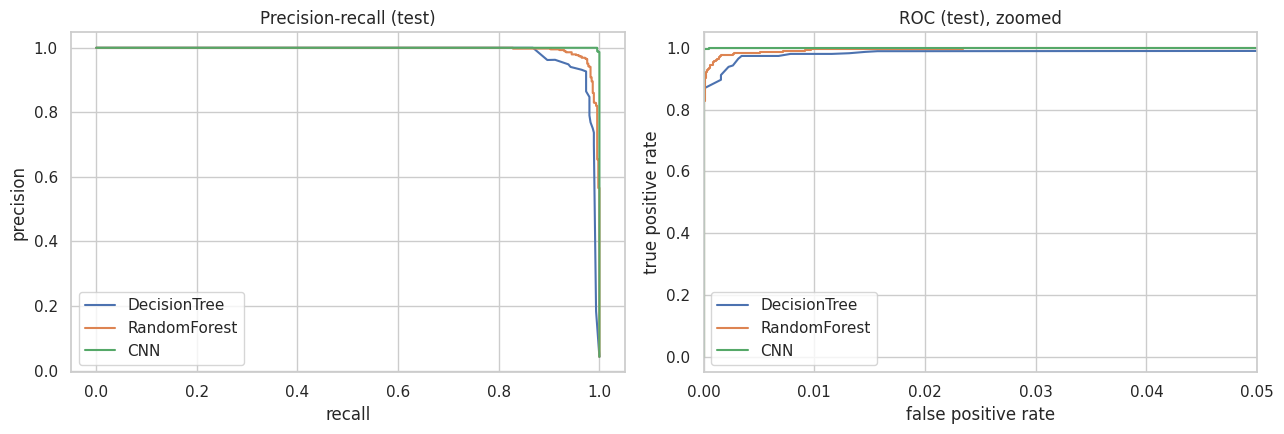

In [24]:
def recall_at_fpr(labels, probs, max_fpr=0.01):
    fpr, tpr, _ = roc_curve(labels, probs)
    return float(tpr[fpr <= max_fpr].max())


comparison = pd.DataFrame({name: evaluate_scores(labels_by_split['test'], probs, thresholds[name])
                           for name, probs in window_probs_test.items()}).T
comparison['recall_at_1pct_FPR'] = [recall_at_fpr(labels_by_split['test'], window_probs_test[n]) for n in comparison.index]
print(comparison.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, probs in window_probs_test.items():
    precision, recall, _ = precision_recall_curve(labels_by_split['test'], probs)
    fpr, tpr, _ = roc_curve(labels_by_split['test'], probs)
    axes[0].plot(recall, precision, label=name)
    axes[1].plot(fpr, tpr, label=name)
axes[0].set(title='Precision-recall (test)', xlabel='recall', ylabel='precision')
axes[1].set(title='ROC (test), zoomed', xlabel='false positive rate', ylabel='true positive rate', xlim=(0, 0.05))
axes[0].legend()
axes[1].legend()
plt.tight_layout()
save_figure('compare_models')
plt.show()
comparison.to_csv(f'{OUTPUT_DIR}/test_metrics.csv')

# Error analysis by activity and Subject


=== DecisionTree ===  false alarms: 32 | missed falls: 16
false alarms by activity: {'D11': 17, 'D18': 8, 'D10': 3, 'D06': 2, 'D08': 1, 'D19': 1}
false alarms by subject : {'SA19': 10, 'SA01': 8, 'SE02': 5, 'SA09': 4, 'SA12': 3, 'SA17': 2}
missed falls by activity: {'F10': 6, 'F13': 5, 'F02': 1, 'F11': 1, 'F05': 1, 'F08': 1}
missed falls by subject : {'SA01': 5, 'SA09': 5, 'SA17': 5, 'SA19': 1}

=== RandomForest ===  false alarms: 26 | missed falls: 10
false alarms by activity: {'D11': 13, 'D18': 5, 'D06': 5, 'D04': 2, 'D14': 1}
false alarms by subject : {'SA01': 6, 'SA09': 6, 'SE02': 6, 'SA19': 4, 'SA12': 2, 'SE05': 2}
missed falls by activity: {'F10': 4, 'F11': 2, 'F13': 2, 'F01': 1, 'F14': 1}
missed falls by subject : {'SA09': 4, 'SA01': 3, 'SA19': 2, 'SA17': 1}

=== CNN ===  false alarms: 9 | missed falls: 0
false alarms by activity: {'D06': 7, 'D04': 1, 'D02': 1}
false alarms by subject : {'SA09': 8, 'SA12': 1}
missed falls by activity: {}
missed falls by subject : {}


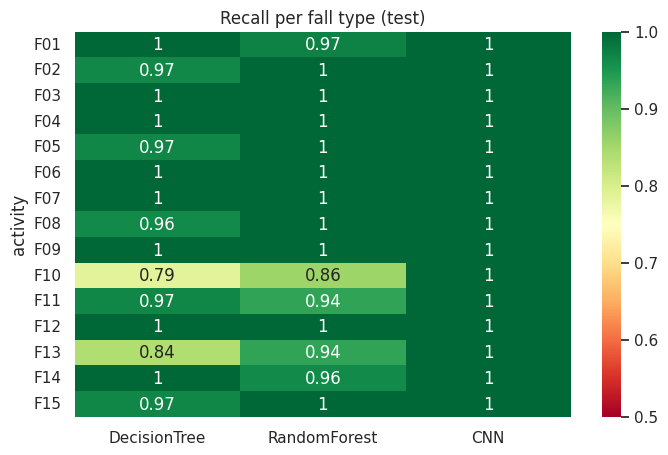

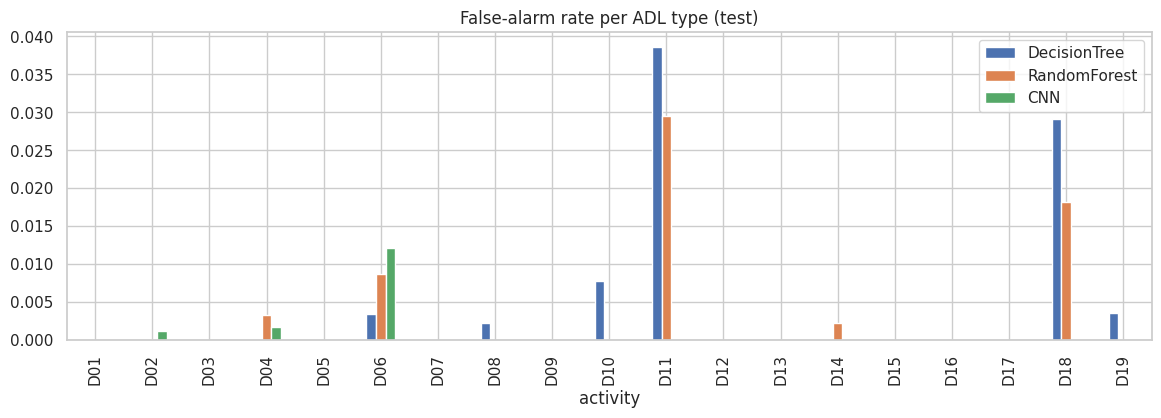

In [25]:
test_windows_meta = window_meta.iloc[split_indices['test']].reset_index(drop=True).copy()
for name, probs in window_probs_test.items():
    test_windows_meta[f'pred_{name}'] = (probs >= thresholds[name]).astype(int)

for name in window_probs_test:
    false_alarms = test_windows_meta[(test_windows_meta.label == 0) & (test_windows_meta[f'pred_{name}'] == 1)]
    missed_falls = test_windows_meta[(test_windows_meta.label == 1) & (test_windows_meta[f'pred_{name}'] == 0)]
    print(f'\n=== {name} ===  false alarms: {len(false_alarms)} | missed falls: {len(missed_falls)}')
    print('false alarms by activity:', false_alarms.activity.value_counts().head(6).to_dict())
    print('false alarms by subject :', false_alarms.subject.value_counts().head(6).to_dict())
    print('missed falls by activity:', missed_falls.activity.value_counts().head(6).to_dict())
    print('missed falls by subject :', missed_falls.subject.value_counts().head(6).to_dict())

recall_by_fall_type = pd.concat([
    test_windows_meta[test_windows_meta.label == 1].groupby('activity')[f'pred_{name}'].mean().rename(name)
    for name in window_probs_test], axis=1).round(3)
plt.figure(figsize=(8, 5))
sns.heatmap(recall_by_fall_type, annot=True, cmap='RdYlGn', vmin=0.5, vmax=1)
plt.title('Recall per fall type (test)')
save_figure('recall_by_fall_type')
plt.show()

false_alarm_rate_by_adl = pd.concat([
    test_windows_meta[test_windows_meta.label == 0].groupby('activity')[f'pred_{name}'].mean().rename(name)
    for name in window_probs_test], axis=1)
false_alarm_rate_by_adl.plot.bar(figsize=(14, 4), title='False-alarm rate per ADL type (test)')
save_figure('false_alarms_by_adl')
plt.show()

# Detection logic and Replay

In [26]:
# Every detector turns one recording into a list of events:
#   dict(impact_idx, alert (True/False), alert_idx, reason)
# reason is 'alert', or the stage that rejected the candidate: 'no_data', 'no_tilt', 'moving'.

LAYER_A_DEFAULTS = dict(
    freefall_g=0.5,                 # |acc| below this just before the impact counts as free-fall
    impact_g_with_freefall=2.0,     # lower impact threshold if free-fall was seen
    impact_g_without_freefall=2.5,  # higher impact threshold if it was not
    tilt_deg=45,                    # minimum orientation change after the impact
    settle_s=1.0,                   # wait for the body to settle before measuring tilt / stillness
    still_s=2.0, still_acc_std_g=0.10,   # stillness window and limit (your architecture spec: 5 s / 0.05 g)
    cooldown_s=20.0)

MODEL_PATH_DEFAULTS = dict(
    impact_gate_g=1.5,              # cheap gate: only run the decision when something hits this hard
    hits_needed=1,                  # consecutive windows above the model threshold
    tilt_deg=0,                     # 0 = orientation check off
    use_stillness=True, settle_s=1.0, still_s=2.0, still_acc_std_g=0.10, still_gyro_dps=30.0,
    cooldown_s=20.0)

REPLAY_STRIDE = 25                  # one decision every 0.5 s
MATCH_TOLERANCE_S = 1.5             # an alert counts for a fall if it is within this time of the impact


def make_event(impact_index, reason, alert_index=None):
    return dict(impact_idx=int(impact_index), alert=(reason == 'alert'), alert_idx=alert_index, reason=reason)


def is_still(sig, start, end, acc_std_limit, gyro_limit_dps=None):
    segment = sig[start:end]
    calm = acc_magnitude(segment).std() < acc_std_limit
    if gyro_limit_dps is not None:
        calm = calm and gyro_magnitude(segment).mean() < gyro_limit_dps
    return calm


def orientation_changed(sig, impact_index, settle_s, min_tilt_deg):
    """Compare the gravity direction before the impact with the direction after the body has settled."""
    before_start = max(0, impact_index - seconds_to_samples(1.5))
    before_end = max(before_start + 1, impact_index - seconds_to_samples(0.5))
    after_start = impact_index + seconds_to_samples(settle_s)
    before = sig[before_start:before_end, :3].mean(0)
    after = sig[after_start:after_start + MODEL_FS_HZ, :3].mean(0)
    return tilt_angle_deg(before, after) > min_tilt_deg


def layer_a_events(sig, params):
    """Layer A: impact (optional free-fall) -> orientation change -> stillness. No machine learning."""
    events, last_alert_end = [], -10 ** 9
    acc_mag = acc_magnitude(sig)
    peaks, _ = find_peaks(acc_mag, height=params['impact_g_with_freefall'], distance=seconds_to_samples(1.0))
    for peak in peaks:
        if peak - last_alert_end < seconds_to_samples(params['cooldown_s']):
            continue
        saw_freefall = peak > 0 and acc_mag[max(0, peak - seconds_to_samples(1.0)):peak].min() < params['freefall_g']
        needed_g = params['impact_g_with_freefall'] if saw_freefall else params['impact_g_without_freefall']
        if acc_mag[peak] < needed_g:
            continue
        after_start = peak + seconds_to_samples(params['settle_s'])
        after_end = after_start + seconds_to_samples(params['still_s'])
        if max(after_end, after_start + MODEL_FS_HZ) > len(sig):
            events.append(make_event(peak, 'no_data'))                      # recording ends too early to check
        elif not orientation_changed(sig, peak, params['settle_s'], params['tilt_deg']):
            events.append(make_event(peak, 'no_tilt'))
        elif not is_still(sig, after_start, after_end, params['still_acc_std_g']):
            events.append(make_event(peak, 'moving'))
        else:
            events.append(make_event(peak, 'alert', after_end))
            last_alert_end = after_end
    return events


def model_path_events(sig, window_starts, window_probs, threshold, params):
    """Model path: impact gate -> model score -> persistence -> optional orientation -> optional stillness."""
    events, last_impact, last_alert_end, hits = [], -10 ** 9, -10 ** 9, 0
    for start, prob in zip(window_starts, window_probs):
        end = start + WINDOW_LEN
        if start <= last_impact or end - last_alert_end < seconds_to_samples(params['cooldown_s']):
            continue
        window_acc = acc_magnitude(sig[start:end])
        if window_acc.max() < params['impact_gate_g'] or prob < threshold:
            hits = 0
            continue
        hits += 1
        if hits < params['hits_needed']:
            continue
        hits = 0
        impact = start + int(window_acc.argmax())
        last_impact = impact
        after_start = impact + seconds_to_samples(params['settle_s'])
        after_end = after_start + seconds_to_samples(params['still_s'])
        needs_data_until = after_end if params['use_stillness'] else after_start + MODEL_FS_HZ
        if (params['tilt_deg'] > 0 or params['use_stillness']) and needs_data_until > len(sig):
            events.append(make_event(impact, 'no_data'))
        elif params['tilt_deg'] > 0 and not orientation_changed(sig, impact, params['settle_s'], params['tilt_deg']):
            events.append(make_event(impact, 'no_tilt'))
        elif params['use_stillness'] and not is_still(sig, after_start, after_end,
                                                      params['still_acc_std_g'], params['still_gyro_dps']):
            events.append(make_event(impact, 'moving'))
        else:
            alert_index = after_end if params['use_stillness'] else end
            events.append(make_event(impact, 'alert', alert_index))
            last_alert_end = alert_index
    return events


def fuse_events(layer_a_list, model_list, window_starts, window_probs, threshold):
    """Fusion rule: a Layer A alert can never be silenced by the model. A model alert can add detections.
    An alert the model agrees with is high priority; Layer A alone is low priority (longer cancel window)."""
    tolerance = seconds_to_samples(MATCH_TOLERANCE_S)
    tagged = [(e, 'layer_a') for e in layer_a_list if e['alert']] + [(e, 'model') for e in model_list if e['alert']]
    fused = []
    for event, source in sorted(tagged, key=lambda item: item[0]['impact_idx']):
        if fused and event['impact_idx'] - fused[-1]['impact_idx'] <= tolerance:
            group = fused[-1]
            group['alert_idx'] = min(group['alert_idx'], event['alert_idx'])
        else:
            group = make_event(event['impact_idx'], 'alert', event['alert_idx'])
            group['sources'] = set()
            fused.append(group)
        group['sources'].add(source)
    for group in fused:
        covering = (window_starts <= group['impact_idx']) & (group['impact_idx'] < window_starts + WINDOW_LEN)
        model_agrees = 'model' in group['sources'] or (covering.any() and window_probs[covering].max() >= threshold)
        group['high_priority'] = bool(model_agrees)
    return fused


def replay_probabilities(subset, predict_fn):
    """Slide a window over every recording of a split and score all windows in one model call."""
    chunks, starts_by_rec = [], {}
    for rec in subset.itertuples():
        sig = signals_50hz[rec.recording_id]
        if len(sig) < WINDOW_LEN:
            continue
        chunk = sliding_window_view(sig, WINDOW_LEN, axis=0)[::REPLAY_STRIDE].transpose(0, 2, 1)
        chunks.append(np.ascontiguousarray(chunk))
        starts_by_rec[rec.recording_id] = np.arange(len(chunk)) * REPLAY_STRIDE
    all_probs = predict_fn(np.concatenate(chunks))
    result, offset = {}, 0
    for rec_id, starts in starts_by_rec.items():
        result[rec_id] = (starts, all_probs[offset:offset + len(starts)])
        offset += len(starts)
    return result


def score_replay(subset, events_by_rec):
    """Detection rate, false alarms per hour, latency and the reason for every miss."""
    tolerance = seconds_to_samples(MATCH_TOLERANCE_S)
    n_falls = detected = fa_events = fa_low_priority = falls_low_priority = 0
    adl_hours, latencies = 0.0, []
    miss_reasons, fa_by_activity = Counter(), Counter()
    for rec in subset.itertuples():
        events = events_by_rec.get(rec.recording_id, [])
        alerts = [e for e in events if e['alert']]
        if rec.label == 0:
            adl_hours += rec.n_samples_50hz / MODEL_FS_HZ / 3600
            fa_events += len(alerts)
            fa_low_priority += sum(not e.get('high_priority', True) for e in alerts)
            fa_by_activity.update([rec.activity] * len(alerts))
            continue
        n_falls += 1
        near = [e for e in events if abs(e['impact_idx'] - rec.impact_index) <= tolerance]
        near_alerts = [e for e in near if e['alert']]
        if near_alerts:
            detected += 1
            latencies.append((near_alerts[0]['alert_idx'] - rec.impact_index) / MODEL_FS_HZ)
            falls_low_priority += not any(e.get('high_priority', True) for e in near_alerts)
        else:
            miss_reasons[near[0]['reason'] if near else 'no_impact_candidate'] += 1
    return dict(falls=n_falls, detection=round(detected / max(n_falls, 1), 4),
                false_alarm_events=fa_events, adl_hours=round(adl_hours, 2),
                false_alarms_per_hour=round(fa_events / max(adl_hours, 1e-9), 2),
                latency_s_median=round(float(np.median(latencies)), 2) if latencies else None,
                misses=dict(miss_reasons), false_alarms_by_activity=dict(fa_by_activity.most_common(3)),
                falls_low_priority=int(falls_low_priority), false_alarms_low_priority=int(fa_low_priority))


def replay_layer_a(subset, params):
    return {r.recording_id: layer_a_events(signals_50hz[r.recording_id], params) for r in subset.itertuples()}


def replay_model_path(subset, probs_by_rec, threshold, params):
    return {rec_id: model_path_events(signals_50hz[rec_id], starts, probs, threshold, params)
            for rec_id, (starts, probs) in probs_by_rec.items()}


def replay_fusion(subset, probs_by_rec, threshold, layer_a_params, model_params):
    layer_a = replay_layer_a(subset, layer_a_params)
    model = replay_model_path(subset, probs_by_rec, threshold, model_params)
    return {rec_id: fuse_events(layer_a.get(rec_id, []), model.get(rec_id, []), starts, probs, threshold)
            for rec_id, (starts, probs) in probs_by_rec.items()}


predict_fns = {
    'CNN': lambda w: cnn_model.predict(normalize_windows(w), batch_size=2048, verbose=0).ravel(),
    'RandomForest': lambda w: forest_model.predict_proba(extract_features(w)[FEATURE_COLUMNS].values)[:, 1],
}

# Choose the settings on the validation subjects
(Never choose settings on test. Read the tables, then copy your picks into Cell 27)

In [27]:
val_recordings = recordings[recordings.split == 'val'].reset_index(drop=True)
val_probs = {name: replay_probabilities(val_recordings, fn) for name, fn in predict_fns.items()}
flat_columns = ['detection', 'false_alarm_events', 'false_alarms_per_hour', 'latency_s_median', 'misses', 'false_alarms_by_activity']

# --- Layer A: impact threshold x orientation threshold x stillness spec ---
layer_a_rows = []
for impact_g in [2.5, 2.0, 1.5]:                 # 2.5 = free-fall does not lower the threshold
    for tilt in [30, 45, 60]:
        for still_s, still_std in [(2.0, 0.10), (5.0, 0.05)]:          # second pair = your architecture spec
            params = {**LAYER_A_DEFAULTS, 'impact_g_with_freefall': impact_g, 'tilt_deg': tilt,
                      'still_s': still_s, 'still_acc_std_g': still_std}
            result = score_replay(val_recordings, replay_layer_a(val_recordings, params))
            layer_a_rows.append(dict(impact_g=impact_g, tilt_deg=tilt, stillness=f'{still_s:g}s/{still_std}',
                                     **{k: result[k] for k in flat_columns}))
pd.set_option('display.max_colwidth', 80)
print('Layer A (validation)')
print(pd.DataFrame(layer_a_rows).to_string(index=False))

# --- model path: gate x orientation x persistence ---
model_rows = []
for name in ['CNN', 'RandomForest']:
    for gate in [2.0, 1.5]:
        for tilt in [0, 30, 45]:                 # 0 = orientation check off
            for hits in [1, 2]:
                params = {**MODEL_PATH_DEFAULTS, 'impact_gate_g': gate, 'tilt_deg': tilt, 'hits_needed': hits}
                events = replay_model_path(val_recordings, val_probs[name], thresholds[name], params)
                result = score_replay(val_recordings, events)
                model_rows.append(dict(model=name, gate_g=gate, tilt_deg=tilt, hits_needed=hits,
                                       **{k: result[k] for k in flat_columns}))
print('\nModel path (validation)')
print(pd.DataFrame(model_rows).to_string(index=False))

Layer A (validation)
 impact_g  tilt_deg stillness  detection  false_alarm_events  false_alarms_per_hour  latency_s_median                                                                misses       false_alarms_by_activity
      2.5        30    2s/0.1     0.9633                  14                   6.03               3.0                 {'no_tilt': 3, 'moving': 5, 'no_impact_candidate': 3} {'D11': 6, 'D09': 4, 'D08': 3}
      2.5        30   5s/0.05     0.8567                   5                   2.15               6.0  {'no_data': 29, 'no_tilt': 3, 'moving': 8, 'no_impact_candidate': 3}           {'D11': 4, 'D09': 1}
      2.5        45    2s/0.1     0.9567                   6                   2.58               3.0                 {'no_tilt': 5, 'moving': 5, 'no_impact_candidate': 3} {'D11': 3, 'D09': 2, 'D14': 1}
      2.5        45   5s/0.05     0.8500                   1                   0.43               6.0  {'no_data': 29, 'no_tilt': 5, 'moving': 8, 'no_impact_candidate'

# Final testing

In [28]:
FINAL_LAYER_A = {**LAYER_A_DEFAULTS}                                   # replace with your validation picks
FINAL_MODEL_PATH = {**MODEL_PATH_DEFAULTS}
FUSION_MODEL = 'CNN'

test_recordings = recordings[recordings.split == 'test'].reset_index(drop=True)
test_probs = {name: replay_probabilities(test_recordings, fn) for name, fn in predict_fns.items()}

final_results = {'Layer A': score_replay(test_recordings, replay_layer_a(test_recordings, FINAL_LAYER_A))}
for name in ['CNN', 'RandomForest']:
    final_results[f'{name} path'] = score_replay(
        test_recordings, replay_model_path(test_recordings, test_probs[name], thresholds[name], FINAL_MODEL_PATH))
final_results['Fusion (Layer A + CNN)'] = score_replay(
    test_recordings, replay_fusion(test_recordings, test_probs[FUSION_MODEL], thresholds[FUSION_MODEL],
                                   FINAL_LAYER_A, FINAL_MODEL_PATH))
print('TEST subjects (do not tune on these numbers)')
print(pd.DataFrame(final_results).T.to_string())
pd.DataFrame(final_results).T.to_csv(f'{OUTPUT_DIR}/replay_test_results.csv')

TEST subjects (do not tune on these numbers)
                       falls detection false_alarm_events adl_hours false_alarms_per_hour latency_s_median                                     misses         false_alarms_by_activity falls_low_priority false_alarms_low_priority
Layer A                  375    0.9547                  7      2.99                  2.34              3.0  {'no_tilt': 13, 'no_impact_candidate': 4}   {'D11': 3, 'D09': 1, 'D13': 1}                  0                         0
CNN path                 375       1.0                  2      2.99                  0.67              3.0                                         {}             {'D06': 1, 'D17': 1}                  0                         0
RandomForest path        375    0.9893                 19      2.99                  6.36              3.0                 {'no_impact_candidate': 4}  {'D11': 12, 'D06': 6, 'D14': 1}                  0                         0
Fusion (Layer A + CNN)   375       1.0     

# Hardware Integration

### 1. SisFall Axis frame

In [29]:
# (run after 12)The angle between the two postures should come out close to 90°.
def mean_gravity_direction(recording_ids, last_second_only=False):
    """Average direction of gravity (unit vector) over a group of recordings, plus its spread in degrees."""
    vectors = []
    for rec_id in recording_ids:
        acc = signals_50hz[rec_id][:, :3]
        mean_vector = acc[-MODEL_FS_HZ:].mean(0) if last_second_only else acc.mean(0)
        vectors.append(mean_vector / np.linalg.norm(mean_vector))
    vectors = np.array(vectors)
    mean_direction = vectors.mean(0) / np.linalg.norm(vectors.mean(0))
    spread_deg = float(tilt_angle_deg(vectors, mean_direction[None, :]).std())
    return mean_direction, spread_deg


walking_ids = recordings[recordings.activity.isin(['D01', 'D02'])].recording_id.iloc[:80]
forward_fall_ids = recordings[recordings.activity.isin(['F01', 'F04'])].recording_id.iloc[:80]
SISFALL_STANDING_GRAVITY, standing_spread = mean_gravity_direction(walking_ids)
SISFALL_PRONE_GRAVITY, prone_spread = mean_gravity_direction(forward_fall_ids, last_second_only=True)

print('gravity while walking (standing posture):', SISFALL_STANDING_GRAVITY.round(2), '| spread', round(standing_spread, 1), 'deg')
print('gravity after forward falls (lying)     :', SISFALL_PRONE_GRAVITY.round(2), '| spread', round(prone_spread, 1), 'deg')
print('angle between the two postures          :',
      round(float(tilt_angle_deg(SISFALL_STANDING_GRAVITY, SISFALL_PRONE_GRAVITY)), 0), 'deg (expect close to 90)')

gravity while walking (standing posture): [ 0.01 -0.98 -0.19] | spread 5.8 deg
gravity after forward falls (lying)     : [-0.21  0.19 -0.96] | spread 29.2 deg
angle between the two postures          : 91.0 deg (expect close to 90)


# Device logs to model input
(Loads a 200 Hz log, fits the axis map from two still recordings, and converts device data to the SisFall frame with the same filter used in training.)

In [30]:
from scipy.spatial.transform import Rotation

GRAVITY_MS2 = 9.80665
RAD_TO_DEG = 57.29578


def load_device_log(path, accel_unit='m/s2', gyro_unit='rad/s'):
    """Read a JSON-lines log (one object per sample) and convert to g and deg/s.
    Expected keys: t_us (or uptime_ms), accel{x,y,z}, gyro{x,y,z}. The log must be sampled at 150 Hz or more."""
    rows = []
    for line in open(path):
        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            continue                                                # skip truncated lines
        time_us = record.get('t_us', record.get('uptime_ms', np.nan) * 1000)
        rows.append([time_us, *(record['accel'][k] for k in 'xyz'), *(record['gyro'][k] for k in 'xyz')])
    data = np.array(rows, dtype=float)
    time_s = (data[:, 0] - data[0, 0]) / 1e6
    acc_g = data[:, 1:4] / (GRAVITY_MS2 if accel_unit == 'm/s2' else 1.0)
    gyro_dps = data[:, 4:7] * (RAD_TO_DEG if gyro_unit == 'rad/s' else 1.0)
    dt = np.diff(time_s)
    print(f'{len(time_s)} samples | rate {1 / np.median(dt):.1f} Hz | 99th percentile gap {np.percentile(dt, 99) * 1000:.1f} ms '
          f'| gaps > 3x median: {(dt > 3 * np.median(dt)).sum()}')
    assert 1 / np.median(dt) >= 150, 'log rate is too low for this pipeline'
    return time_s, acc_g, gyro_dps


def fit_axis_map(standing_acc_g, prone_acc_g):
    """From two still recordings of the worn device (upright, then lying face-down) find the rotation that maps
    the device axes onto the SisFall axes. Returns (3x3 matrix, fit error: small is good)."""
    unit = lambda v: v / np.linalg.norm(v)
    reference = [SISFALL_STANDING_GRAVITY, SISFALL_PRONE_GRAVITY]
    measured = [unit(standing_acc_g.mean(0)), unit(prone_acc_g.mean(0))]
    rotation, fit_error = Rotation.align_vectors(reference, measured)
    return rotation.as_matrix(), float(fit_error)


def snap_to_axes(matrix):
    """If the sensor is mounted axis-aligned, round the matrix to 0 / +-1 (keeps it only if still a proper rotation)."""
    snapped = np.zeros_like(matrix)
    for row in range(3):
        col = np.abs(matrix[row]).argmax()
        snapped[row, col] = np.sign(matrix[row, col])
    is_rotation = np.allclose(snapped @ snapped.T, np.eye(3)) and np.isclose(np.linalg.det(snapped), 1.0)
    return snapped if is_rotation else matrix


def device_to_model_signal(time_s, acc_g, gyro_dps, still_range_s=(0, 8), axis_map=None):
    """Device log -> 50 Hz signal in the SisFall frame, using exactly the training-time filter.
    still_range_s must be a stretch where the device does not move at all (used for bias and scale)."""
    axis_map = np.array(HARDWARE['axis_map'] if axis_map is None else axis_map)
    grid = np.arange(0, time_s[-1], 1 / RAW_FS_HZ)                          # uniform 200 Hz time grid
    acc = np.column_stack([np.interp(grid, time_s, acc_g[:, c]) for c in range(3)])
    gyro = np.column_stack([np.interp(grid, time_s, gyro_dps[:, c]) for c in range(3)])
    still = (grid >= still_range_s[0]) & (grid < still_range_s[1])
    gyro = gyro - gyro[still].mean(0)                                       # remove the gyro bias
    acc = acc / np.linalg.norm(acc[still].mean(0))                          # make resting gravity exactly 1 g
    in_sisfall_frame = np.concatenate([acc @ axis_map.T, gyro @ axis_map.T], axis=1)
    return lowpass_and_decimate(in_sisfall_frame.astype(np.float32))


# Usage once you have the two still logs (worn upright, worn lying face-down):
#   t, standing_acc, g = load_device_log('.../standing.jsonl')
#   t, prone_acc, g = load_device_log('.../prone.jsonl')
#   matrix, error = fit_axis_map(standing_acc, prone_acc)
#   HARDWARE['axis_map'] = snap_to_axes(matrix).tolist()
#   print(np.round(HARDWARE['axis_map'], 2), '| fit error', round(error, 3))

# Transfer test on your own recording

In [31]:
DEVICE_LOG_PATH = f'{OUTPUT_DIR}/device_logs/fall_test_01.jsonl'      # your own 200 Hz recording


def check_device_recording(log_path, still_range_s=(0, 8)):
    time_s, acc_g, gyro_dps = load_device_log(log_path)
    device_signal = device_to_model_signal(time_s, acc_g, gyro_dps, still_range_s)
    starts = np.arange(0, len(device_signal) - WINDOW_LEN + 1, REPLAY_STRIDE)
    device_windows = np.stack([device_signal[s:s + WINDOW_LEN] for s in starts])
    probs = {name: fn(device_windows) for name, fn in predict_fns.items()}
    layer_a = layer_a_events(device_signal, FINAL_LAYER_A)
    cnn_alerts = model_path_events(device_signal, starts, probs['CNN'], thresholds['CNN'], FINAL_MODEL_PATH)

    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    seconds = np.arange(len(device_signal)) / MODEL_FS_HZ
    axes[0].plot(seconds, acc_magnitude(device_signal))
    axes[0].set_ylabel('|acceleration| (g)')
    for name, p in probs.items():
        axes[1].plot((starts + WINDOW_LEN / 2) / MODEL_FS_HZ, p, label=name)
    axes[1].axhline(thresholds['CNN'], color='gray', linestyle='--')
    axes[1].set(ylabel='fall probability', xlabel='time (s)')
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    print('Layer A events:', [(e['impact_idx'] / MODEL_FS_HZ, e['reason']) for e in layer_a])
    print('CNN path events:', [(e['impact_idx'] / MODEL_FS_HZ, e['reason']) for e in cnn_alerts])


if os.path.exists(DEVICE_LOG_PATH):
    check_device_recording(DEVICE_LOG_PATH)
else:
    print('No device log yet. Record the MPU6050 at 200 Hz (see the hardware checklist), then set DEVICE_LOG_PATH.')

No device log yet. Record the MPU6050 at 200 Hz (see the hardware checklist), then set DEVICE_LOG_PATH.


# Export

In [32]:
dump(tree_model, f'{OUTPUT_DIR}/decision_tree.joblib')
dump(forest_model, f'{OUTPUT_DIR}/random_forest.joblib')
cnn_model.save(f'{OUTPUT_DIR}/cnn_fall.keras')

preprocessing = dict(
    gyro_scale=GYRO_SCALE, gyro_dps_per_count=GYRO_DPS_PER_COUNT, model_fs_hz=MODEL_FS_HZ,
    window_len=WINDOW_LEN, window_stride=WINDOW_STRIDE, lowpass_sos=LOWPASS_SOS.tolist(),
    norm_mean=norm_mean.tolist(), norm_std=norm_std.tolist(),
    thresholds={k: float(v) for k, v in thresholds.items()}, feature_names=FEATURE_COLUMNS,
    layer_a=FINAL_LAYER_A, model_path=FINAL_MODEL_PATH, hardware=HARDWARE,
    tree_params=tree_params, forest_params={k: str(v) for k, v in forest_params.items()},
    subject_splits=SUBJECT_SPLITS, seed=SEED)
json.dump(preprocessing, open(f'{OUTPUT_DIR}/preprocessing.json', 'w'), indent=2)


def c_float_list(values):
    return ', '.join(f'{v:.8e}f' for v in np.ravel(values))


def write_firmware_header(path):
    """Everything the firmware must reproduce exactly: filter, normalisation, threshold, FSM settings."""
    with open(path, 'w') as header:
        header.write(f'#pragma once\n#define FS_MODEL {MODEL_FS_HZ}\n#define WIN_LEN {WINDOW_LEN}\n')
        sos_rows = ',\n  '.join('{' + c_float_list(row) + '}' for row in LOWPASS_SOS)
        header.write(f'static const float LP_SOS[{len(LOWPASS_SOS)}][6] = {{\n  {sos_rows}\n}};\n')
        header.write(f'static const float NORM_MEAN[6] = {{{c_float_list(norm_mean)}}};\n')
        header.write(f'static const float NORM_STD[6] = {{{c_float_list(norm_std)}}};\n')
        header.write(f'static const float CNN_THRESHOLD = {thresholds["CNN"]:.5f}f;\n')
        header.write(f'static const float RF_THRESHOLD = {thresholds["RandomForest"]:.5f}f;\n')
        for key, value in FINAL_LAYER_A.items():
            header.write(f'#define LAYER_A_{key.upper()} {value}\n')


write_firmware_header(f'{OUTPUT_DIR}/sentinel_params.h')

try:                                                   # Random Forest -> C code (check the API of your emlearn version)
    import emlearn
    emlearn.convert(forest_model, method='inline').save(file=f'{OUTPUT_DIR}/fall_rf.h', name='fall_rf')
    print('random forest exported to fall_rf.h')
except Exception as error:
    print('emlearn export skipped:', error)
print(sorted(os.listdir(OUTPUT_DIR)))

emlearn export skipped: No module named 'emlearn'
['cnn_fall.keras', 'cnn_fall_int8.tflite', 'dataset_config.json', 'decision_tree.joblib', 'features.csv', 'plots', 'preprocessing.json', 'random_forest.joblib', 'recordings_meta.csv', 'replay_test_results.csv', 'sentinel_params.h', 'signals_50hz.joblib', 'test_metrics.csv', 'window_meta.csv', 'windows_50hz_2s.npz']


# Quantize the CNN to int8

In [33]:
def quantize_cnn(representative_windows, n_samples=500):
    """int8 TensorFlow Lite model. Use windows that look like the real input (device windows if you have them)."""
    chosen = np.random.RandomState(SEED).choice(len(representative_windows), min(n_samples, len(representative_windows)), replace=False)

    def representative_data():
        for i in chosen:
            yield [normalize_windows(representative_windows[i:i + 1])]

    converter = tf.lite.TFLiteConverter.from_keras_model(cnn_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    return converter.convert()


def tflite_predict(tflite_bytes, normalized_windows):
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    input_info, output_info = interpreter.get_input_details()[0], interpreter.get_output_details()[0]
    in_scale, in_zero = input_info['quantization']
    out_scale, out_zero = output_info['quantization']
    probs = []
    for window in normalized_windows:
        quantized = np.clip(np.round(window / in_scale + in_zero), -128, 127).astype(np.int8)[None]
        interpreter.set_tensor(input_info['index'], quantized)
        interpreter.invoke()
        probs.append((interpreter.get_tensor(output_info['index'])[0, 0].astype(np.float32) - out_zero) * out_scale)
    return np.array(probs)


tflite_bytes = quantize_cnn(windows[split_indices['train']])
open(f'{OUTPUT_DIR}/cnn_fall_int8.tflite', 'wb').write(tflite_bytes)
print('int8 model size:', round(len(tflite_bytes) / 1024, 1), 'KB')

check_rows = np.random.RandomState(SEED).choice(len(split_indices['test']), min(3000, len(split_indices['test'])), replace=False)
test_inputs = normalize_windows(windows[split_indices['test']][check_rows])
test_check_labels = labels_by_split['test'][check_rows]
float_probs = window_probs_test['CNN'][check_rows]
int8_probs = tflite_predict(tflite_bytes, test_inputs)
print('PR-AUC float:', round(average_precision_score(test_check_labels, float_probs), 4),
      '| int8:', round(average_precision_score(test_check_labels, int8_probs), 4))
print('same decision as the float model:',
      round(float(((float_probs >= thresholds['CNN']) == (int8_probs >= thresholds['CNN'])).mean()), 4))

Saved artifact at '/tmp/tmpvzxh96mn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 100, 6), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  137919253319888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137918992092048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919255112848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919011805264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919254754320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919255112080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919255114576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919255112272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919255112656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919255109968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137919255110736: Te

# Inference

In [41]:
import numpy as np
rng = np.random.default_rng(0)
FS = 200

def base(seconds):
    n = int(seconds * FS)
    x = np.zeros((n, 6))
    x[:, 2] = 1.0                                   # standing: gravity on z
    return x

def noise(x, s=0.02):
    return x + rng.normal(0, s, x.shape)

# 1) Standing still (expect: no fall)
standing = noise(base(10))

# 2) Walking (expect: no fall)
t = np.arange(10 * FS) / FS
walking = base(10)
walking[:, 2] += 0.3 * np.sin(2 * np.pi * 2 * t)            # ~2 Hz step bounce
walking[:, 0] += 0.2 * np.sin(2 * np.pi * 1 * t)
walking[:, 3:] += 25 * np.sin(2 * np.pi * 2 * t)[:, None]   # arm swing
walking = noise(walking)

# 3) Fall: free-fall dip -> impact -> lying still on side (expect: fall)
fall = base(12)
i = int(5 * FS)
fall[i - 40:i, :3] = [0.1, 0.1, 0.2]                         # free-fall (<0.5 g) for 0.2 s
fall[i - 40:i, 3:] = 150                                     # rotating while falling
fall[i:i + 6, :3] = [2.0, 1.5, 4.5]                          # impact spike
fall[i + 6:, :3] = [1.0, 0.0, 0.0]                           # lying: gravity now on x
fall[i + 6:, 3:] = 0
fall = noise(fall, 0.01)

# 4) Sitting down hard (expect: no fall, harder case)
sit = base(10)
j = int(4 * FS)
sit[j:j + 8, 2] = 2.2
sit[j + 8:, :3] = [0.7, 0.0, 0.7]                            # tilted ~45 deg, then still
sit = noise(sit)

# 5) Jumping (expect: no fall, harder case)
jump = base(10)
k = int(4 * FS)
jump[k:k + 30, :3] = 0.2                                     # airborne
jump[k + 30:k + 36, 2] = 3.5                                 # landing
jump = noise(jump)                                           # keeps moving afterwards in real life

cases = dict(standing=standing, walking=walking, fall=fall, sit_down=sit, jump=jump)
for name, arr in cases.items():
    r = predict_fall(arr, fs_hz=200)
    print(f"{name:10s} fall={r['fall_detected']!s:5}  max_prob={r['max_prob']:.3f}")

standing   fall=False  max_prob=0.000
walking    fall=False  max_prob=0.001
fall       fall=True   max_prob=0.997
sit_down   fall=False  max_prob=0.001
jump       fall=False  max_prob=0.007


In [42]:
test_idx = split_indices['test']
meta = window_meta.iloc[test_idx].reset_index(drop=True)
w = windows[test_idx]

# one fall and one ADL window per type
cases = {
    'fall F05 (forward)':  w[meta[(meta.activity == 'F05')].index[0]],
    'fall F01':            w[meta[(meta.activity == 'F01')].index[0]],
    'ADL D01 (walking)':   w[meta[(meta.activity == 'D01')].index[0]],
    'ADL D11 (jump?)':     w[meta[(meta.activity == 'D11')].index[0]],
    'ADL D17 (sit/lie)':   w[meta[(meta.activity == 'D17')].index[0]],
}
for name, win in cases.items():
    r = predict_fall(win, fs_hz=50)
    print(f"{name:22s} fall={r['fall_detected']!s:5}  prob={r['max_prob']:.3f}")

fall F05 (forward)     fall=True   prob=0.998
fall F01               fall=True   prob=1.000
ADL D01 (walking)      fall=False  prob=0.000
ADL D11 (jump?)        fall=False  prob=0.000
ADL D17 (sit/lie)      fall=False  prob=0.000


In [43]:
import json, numpy as np
from scipy import signal
import tensorflow as tf

def predict_fall(data, fs_hz=200, model_dir='/content/drive/MyDrive/SENTINEL_X',
                 accel_unit='g', gyro_unit='deg/s', threshold=None):
    """
    data   : (n, 6) array [ax ay az (g), gx gy gz (deg/s)] in the SisFall axis frame
    fs_hz  : sampling rate of data (200 = filter + decimate, 50 = already model-ready)
    Returns: dict(fall_detected, max_prob, probs, window_starts)
    """
    model = tf.keras.models.load_model(f'{model_dir}/cnn_fall.keras', compile=False)
    cfg = json.load(open(f'{model_dir}/preprocessing.json'))
    sos = np.array(cfg['lowpass_sos'])
    mean, std = np.array(cfg['norm_mean'], np.float32), np.array(cfg['norm_std'], np.float32)
    thr = cfg['thresholds']['CNN'] if threshold is None else threshold
    WIN, FS_MODEL, STRIDE = cfg['window_len'], cfg['model_fs_hz'], 25

    x = np.asarray(data, np.float64).copy()
    if accel_unit == 'm/s2': x[:, :3] /= 9.80665
    if gyro_unit == 'rad/s': x[:, 3:] *= 57.29578

    if fs_hz != FS_MODEL:                                   # resample to 200 Hz, low-pass, decimate to 50 Hz
        t = np.arange(len(x)) / fs_hz
        grid = np.arange(0, t[-1], 1 / 200)
        x = np.column_stack([np.interp(grid, t, x[:, c]) for c in range(6)])
        zi = signal.sosfilt_zi(sos)
        x = np.column_stack([signal.sosfilt(sos, x[:, c], zi=zi * x[0, c])[0] for c in range(6)])
        x = x[::200 // FS_MODEL]

    if len(x) < WIN:                                        # pad short input to 2 s
        x = np.pad(x, ((0, WIN - len(x)), (0, 0)), mode='edge')

    starts = np.arange(0, len(x) - WIN + 1, STRIDE)
    windows = np.stack([x[s:s + WIN] for s in starts]).astype(np.float32)
    probs = model.predict((windows - mean) / std, verbose=0).ravel()

    return dict(fall_detected=bool((probs >= thr).any()), max_prob=float(probs.max()),
                probs=probs, window_starts=starts)

In [44]:
my_array = fall
res = predict_fall(my_array, fs_hz=200)
print(f"Fall Detected: {res['fall_detected']} | Peak Probability: {res['max_prob']:.4f}")

Fall Detected: True | Peak Probability: 0.9972
